# Projet academy — Analyse exploratoire des données éducatives mondiales

## Contexte du projet

academy est une start-up EdTech spécialisée dans les contenus de formation en ligne à destination des lycéens et des étudiants universitaires.

Dans le cadre de son projet d'expansion internationale, l'entreprise souhaite étudier les données éducatives de la Banque mondiale afin d'identifier les marchés potentiellement intéressants.

## Objectifs de l'analyse

Cette première analyse exploratoire vise à :

1. Comprendre la structure des cinq jeux de données.
2. Évaluer leur qualité et leur fiabilité.
3. Identifier et supprimer les doublons.
4. Mesurer la proportion de valeurs manquantes.
5. Étudier les variables numériques et catégorielles.
6. Identifier et supprimer les entités qui ne correspondent pas à des pays.
7. Examiner la disponibilité des données selon les années.

**Question principale :** les données éducatives de la Banque mondiale sont-elles suffisamment pertinentes et exploitables pour aider academy à orienter sa stratégie d'expansion internationale ?

## Outils utilisés

- Python : langage de programmation utilisé pour l'analyse.
- Pandas : bibliothèque permettant de manipuler et d'explorer des données structurées.
- Google Colab : environnement d'exécution et de documentation du notebook.

Cette première phase est consacrée à la compréhension et à la fiabilisation des données, avant toute recommandation stratégique.

import : demande à Python de charger une bibliothèque.

pandas : bibliothèque spécialisée dans la manipulation et l'analyse de données.

as pd : donne un alias plus court à cette bibliothèque.

In [49]:
import pandas as pd

## 1. Chargement des données

Nous commençons par importer les cinq fichiers du jeu de données EdStats.

Les fichiers CSV sont des fichiers de données tabulaires, organisés en lignes et en colonnes.

Nous utilisons la bibliothèque Pandas et sa fonction `read_csv()` pour transformer chaque fichier en DataFrame.

Vérifications de l'existence et du bon chargement du dossier et des fichiers.
**Cette vérification permet d'éviter une erreur courante : FileNotFoundError, qui signifie que Python ne trouve pas le fichier demandé.**

In [50]:
import os

print("Répertoire de travail :", os.getcwd())

print("\nFichiers CSV disponibles :")

for fichier in os.listdir("/content"):
    if fichier.endswith(".csv"):
        print(fichier)

Répertoire de travail : /content

Fichiers CSV disponibles :
EdStatsFootNote.csv
EdStatsCountry.csv
EdStatsCountry-Series.csv
EdStatsSeries.csv
EdStatsData.csv


In [51]:
# Chargement des fichiers CSV & création de 5 variables distinctes pour pouvoir étudier les fichiers indépendamment

country = pd.read_csv("/content/EdStatsCountry.csv")
country_series = pd.read_csv("/content/EdStatsCountry-Series.csv")
data = pd.read_csv("/content/EdStatsData.csv")
footnote = pd.read_csv("/content/EdStatsFootNote.csv")
series = pd.read_csv("/content/EdStatsSeries.csv")

In [52]:
# Affichage des cinq premières lignes du fichier Country

country.head()

,Country Code,Short Name,Table Name,Long Name,2-alpha code,Currency Unit,Special Notes,Region,Income Group,WB-2 code,...,IMF data dissemination standard,Latest population census,Latest household survey,Source of most recent Income and expenditure data,Vital registration complete,Latest agricultural census,Latest industrial data,Latest trade data,Latest water withdrawal data,Unnamed: 31
0,ABW,Aruba,Aruba,Aruba,AW,Aruban florin,SNA data for 2000-2011 are updated from offici...,Latin America & Caribbean,High income: nonOECD,AW,...,NaN,2010,NaN,NaN,Yes,NaN,NaN,2012.0,NaN,NaN
1,AFG,Afghanistan,Afghanistan,Islamic State of Afghanistan,AF,Afghan afghani,Fiscal year end: March 20; reporting period fo...,South Asia,Low income,AF,...,General Data Dissemination System (GDDS),1979,"Multiple Indicator Cluster Survey (MICS), 2010/11","Integrated household survey (IHS), 2008",NaN,2013/14,NaN,2012.0,2000,NaN
2,AGO,Angola,Angola,People's Republic of Angola,AO,Angolan kwanza,"April 2013 database update: Based on IMF data,...",Sub-Saharan Africa,Upper middle income,AO,...,General Data Dissemination System (GDDS),1970,"Malaria Indicator Survey (MIS), 2011","Integrated household survey (IHS), 2008",NaN,2015,NaN,NaN,2005,NaN
3,ALB,Albania,Albania,Republic of Albania,AL,Albanian lek,NaN,Europe & Central Asia,Upper middle income,AL,...,General Data Dissemination System (GDDS),2011,"Demographic and Health Survey (DHS), 2008/09",Living Standards Measurement Study Survey (LSM...,Yes,2012,2010.0,2012.0,2006,NaN
4,AND,Andorra,Andorra,Principality of Andorra,AD,Euro,NaN,Europe & Central Asia,High income: nonOECD,AD,...,NaN,2011. Population figures compiled from adminis...,NaN,NaN,Yes,NaN,NaN,2006.0,NaN,NaN


**nb : La méthode head() permet d'afficher un aperçu d'un DataFrame sans devoir consulter l'intégralité des données.**

## 2. Analyse exploratoire du fichier Country

### 2.1. Compréhension de la structure des données

Le fichier `EdStatsCountry.csv` contient des informations géographiques, économiques et démographiques relatives aux pays et à certaines entités statistiques de la Banque mondiale.

**Que représente une ligne ?**

Une ligne correspond à une entité géographique identifiée par un code (`Country Code`). Cette entité peut être un pays ou, potentiellement, un regroupement de pays.

**Que représente une colonne ?**

Chaque colonne correspond à une variable décrivant cette entité.

Par exemple :
- `Country Code` : code identifiant l'entité.
- `Short Name` : nom court du pays ou de l'entité.
- `Region` : région géographique.
- `Income Group` : catégorie de revenu.
- `Currency Unit` : monnaie utilisée.

**Premières observations :**

L'affichage des cinq premières lignes révèle la présence de valeurs manquantes (`NaN`) ainsi que d'une colonne nommée `Unnamed: 31`, dont l'utilité reste à vérifier.

L'objectif des prochaines manipulations est d'évaluer la structure et la qualité des données avant de les utiliser dans une analyse stratégique.

In [53]:
# Récupération du nombre de lignes et de colonnes

nombre_lignes, nombre_colonnes = country.shape

# Affichage des résultats

print("Nombre de lignes :", nombre_lignes)
print("Nombre de colonnes :", nombre_colonnes)

Nombre de lignes : 241
Nombre de colonnes : 32


### 2.2. Dimensions du jeu de données

Nous utilisons l'attribut `shape` de Pandas afin de déterminer le nombre de lignes et de colonnes du DataFrame.

Cette opération permet d'évaluer le volume initial des données et de disposer d'un point de référence avant les opérations de nettoyage.

L'attribut `shape` renvoie un tuple contenant deux valeurs : le nombre de lignes et le nombre de colonnes.

Nous stockons ces deux valeurs dans des variables distinctes afin de faciliter leur réutilisation dans la suite de l'analyse.

**Interprétation :** les résultats obtenus permettent de connaître le nombre initial d'entités géographiques et de variables disponibles dans le fichier Country.

In [54]:
# Affichage des informations générales du DataFrame

country.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 241 entries, 0 to 240
Data columns (total 32 columns):
 #   Column                                             Non-Null Count  Dtype  
---  ------                                             --------------  -----  
 0   Country Code                                       241 non-null    object 
 1   Short Name                                         241 non-null    object 
 2   Table Name                                         241 non-null    object 
 3   Long Name                                          241 non-null    object 
 4   2-alpha code                                       238 non-null    object 
 5   Currency Unit                                      215 non-null    object 
 6   Special Notes                                      145 non-null    object 
 7   Region                                             214 non-null    object 
 8   Income Group                                       214 non-null    object 
 9   WB-2 code 

### 2.3. Identification des types de variables

Nous utilisons la méthode `info()` pour examiner la structure technique du DataFrame.

Cette méthode fournit notamment les types de données et le nombre de valeurs non nulles dans chaque colonne.

Cette vérification est nécessaire pour distinguer les variables numériques des variables catégorielles et identifier d'éventuelles incohérences de format.

Elle permet également de préparer les analyses statistiques et de repérer les colonnes présentant un nombre important de valeurs manquantes.

In [55]:
# Affichage de tous les noms de colonnes

country.columns.tolist()

['Country Code',
 'Short Name',
 'Table Name',
 'Long Name',
 '2-alpha code',
 'Currency Unit',
 'Special Notes',
 'Region',
 'Income Group',
 'WB-2 code',
 'National accounts base year',
 'National accounts reference year',
 'SNA price valuation',
 'Lending category',
 'Other groups',
 'System of National Accounts',
 'Alternative conversion factor',
 'PPP survey year',
 'Balance of Payments Manual in use',
 'External debt Reporting status',
 'System of trade',
 'Government Accounting concept',
 'IMF data dissemination standard',
 'Latest population census',
 'Latest household survey',
 'Source of most recent Income and expenditure data',
 'Vital registration complete',
 'Latest agricultural census',
 'Latest industrial data',
 'Latest trade data',
 'Latest water withdrawal data',
 'Unnamed: 31']

### 2. Identification des doublons

Un doublon correspond à une observation répétée dans un jeu de données. Sa présence peut entraîner des biais dans les analyses statistiques, notamment en donnant artificiellement plus de poids à certaines observations.

Nous utilisons la méthode `duplicated()` de Pandas pour identifier les lignes identiques, puis la méthode `sum()` pour calculer leur nombre.

Nous vérifierons également l'unicité de la variable `Country Code`, qui sert d'identifiant géographique.

Cette seconde vérification permet de détecter les cas où plusieurs lignes possèdent le même identifiant sans être nécessairement identiques sur toutes les colonnes.

In [56]:
# Identifier les lignes entièrement dupliquées
doublons = country.duplicated()

# Calculer le nombre total de doublons
nombre_doublons = doublons.sum()

# Afficher le résultat
print("Nombre de doublons :", nombre_doublons)

Nombre de doublons : 0


In [57]:
# Vérifier les doublons sur l'identifiant Country Code

doublons_codes = country["Country Code"].duplicated().sum()

print("Nombre de codes pays dupliqués :", doublons_codes)

Nombre de codes pays dupliqués : 0


In [58]:
# Suppression des doublons complets

ccountry = country.drop_duplicates()

# Vérification après nettoyage

print("Nombre de lignes après nettoyage :", country.shape[0])
print("Doublons restants :", country.duplicated().sum())

Nombre de lignes après nettoyage : 241
Doublons restants : 0


### Résultats du contrôle des doublons

Le contrôle des doublons a été réalisé en deux étapes :

1. Recherche des lignes entièrement identiques avec `duplicated()`.
2. Vérification de l'unicité de la colonne `Country Code`.

**Résultats :**
- Nombre de doublons complets : à compléter après exécution.
- Nombre de codes géographiques dupliqués : à compléter après exécution.
- Nombre de lignes après nettoyage : à compléter après exécution.

La méthode `drop_duplicates()` a été utilisée pour supprimer les éventuelles répétitions complètes.

Cette vérification contribue à garantir la cohérence du fichier Country avant les prochaines étapes de nettoyage et d'analyse.

### 2.5. Analyse des valeurs manquantes

L'objectif de cette étape est de mesurer la complétude des différentes variables du fichier Country.

Les valeurs manquantes peuvent limiter la fiabilité des analyses et empêcher certaines comparaisons entre pays.

Nous commençons par calculer le nombre de valeurs manquantes pour chaque colonne à l'aide des méthodes `isnull()` et `sum()` de Pandas.

Nous calculerons ensuite leur proportion afin de comparer les colonnes indépendamment du nombre d'observations.

In [59]:
# Calcul du nombre de valeurs manquantes par colonne

valeurs_manquantes = country.isnull().sum()

# Affichage des résultats
print(valeurs_manquantes)

Country Code                                           0
Short Name                                             0
Table Name                                             0
Long Name                                              0
2-alpha code                                           3
Currency Unit                                         26
Special Notes                                         96
Region                                                27
Income Group                                          27
WB-2 code                                              1
National accounts base year                           36
National accounts reference year                     209
SNA price valuation                                   44
Lending category                                      97
Other groups                                         183
System of National Accounts                           26
Alternative conversion factor                        194
PPP survey year                

In [60]:
# Calcul du pourcentage de valeurs manquantes

pourcentage_manquant = country.isnull().mean() * 100

# Affichage des résultats
print(pourcentage_manquant)

Country Code                                           0.000000
Short Name                                             0.000000
Table Name                                             0.000000
Long Name                                              0.000000
2-alpha code                                           1.244813
Currency Unit                                         10.788382
Special Notes                                         39.834025
Region                                                11.203320
Income Group                                          11.203320
WB-2 code                                              0.414938
National accounts base year                           14.937759
National accounts reference year                      86.721992
SNA price valuation                                   18.257261
Lending category                                      40.248963
Other groups                                          75.933610
System of National Accounts             

**La méthode mean() calcule une moyenne. Or, nous savons que les valeurs manquantes sont représentées par True (1) et les valeurs présentes par False (0).**

In [61]:
# Création d'un tableau récapitulatif

qualite_country = pd.DataFrame({
    "Valeurs manquantes": country.isnull().sum(),
    "Pourcentage (%)": country.isnull().mean() * 100
})

# Tri des colonnes par pourcentage décroissant
qualite_country = qualite_country.sort_values(
    by="Pourcentage (%)",
    ascending=False
)

# Affichage du tableau
qualite_country.round(2)

,Valeurs manquantes,Pourcentage (%)
Unnamed: 31,241,100.00
National accounts reference year,209,86.72
Alternative conversion factor,194,80.50
Other groups,183,75.93
Latest industrial data,134,55.60
Vital registration complete,130,53.94
External debt Reporting status,117,48.55
Latest household survey,100,41.49
Latest agricultural census,99,41.08
Lending category,97,40.25


### 2.6. Traitement des colonnes fortement incomplètes

Après avoir calculé le pourcentage de valeurs manquantes, nous cherchons à identifier les variables potentiellement inutilisables.

Nous retenons provisoirement un seuil de 80 % de valeurs manquantes pour repérer les colonnes particulièrement incomplètes.

Ce seuil constitue un choix exploratoire et non une règle statistique universelle. Une variable peut être pertinente malgré un taux élevé de valeurs manquantes.

Avant toute suppression, nous examinerons les colonnes concernées afin de vérifier qu'elles ne sont pas essentielles à l'analyse ou à l'identification des pays.

Cette démarche vise à améliorer l'exploitabilité des données tout en limitant les pertes d'informations utiles.

In [62]:
# Définition du seuil maximal de valeurs manquantes
seuil = 80

# Identification des colonnes dépassant le seuil
colonnes_a_examiner = pourcentage_manquant[
    pourcentage_manquant > seuil
].index.tolist()

# Affichage des colonnes concernées
print("Colonnes à examiner :")
print(colonnes_a_examiner)

Colonnes à examiner :
['National accounts reference year', 'Alternative conversion factor', 'Unnamed: 31']


In [63]:
# Suppression de la colonne entièrement vide

country = country.drop(columns=["Unnamed: 31"])

# Vérification des nouvelles dimensions
print("Dimensions après nettoyage :", country.shape)

Dimensions après nettoyage : (241, 31)


### 2.7. Analyse statistique des variables numériques

Nous utilisons la méthode `describe()` de Pandas pour obtenir les principales statistiques descriptives des variables numériques.

Cette méthode calcule notamment le nombre de valeurs disponibles, la moyenne, l'écart-type, les valeurs minimales et maximales ainsi que les quartiles.

L'objectif est d'examiner la distribution des variables numériques et de repérer d'éventuelles anomalies.

Il convient toutefois de distinguer les variables quantitatives des variables représentant des années ou des identifiants, pour lesquelles certaines statistiques comme la moyenne peuvent être peu pertinentes.

In [64]:
country.describe()

,National accounts reference year,Latest industrial data,Latest trade data
count,32.00000,107.000000,185.000000
mean,2001.53125,2008.102804,2010.994595
std,5.24856,2.616834,2.569675
min,1987.00000,2000.000000,1995.000000
25%,1996.75000,2007.500000,2011.000000
50%,2002.00000,2009.000000,2012.000000
75%,2005.00000,2010.000000,2012.000000
max,2012.00000,2010.000000,2012.000000


In [65]:
# Sélection des colonnes de type texte ou catégorie

colonnes_categorielles = country.select_dtypes(
    include=["object", "category"]
).columns

# Affichage de leurs noms
print(colonnes_categorielles.tolist())

['Country Code', 'Short Name', 'Table Name', 'Long Name', '2-alpha code', 'Currency Unit', 'Special Notes', 'Region', 'Income Group', 'WB-2 code', 'National accounts base year', 'SNA price valuation', 'Lending category', 'Other groups', 'System of National Accounts', 'Alternative conversion factor', 'PPP survey year', 'Balance of Payments Manual in use', 'External debt Reporting status', 'System of trade', 'Government Accounting concept', 'IMF data dissemination standard', 'Latest population census', 'Latest household survey', 'Source of most recent Income and expenditure data', 'Vital registration complete', 'Latest agricultural census', 'Latest water withdrawal data']


In [66]:
# Nombre d'occurrences de chaque région

country["Region"].value_counts(dropna=False)

,count
Region,
Europe & Central Asia,57
Sub-Saharan Africa,48
Latin America & Caribbean,41
East Asia & Pacific,36
NaN,27
Middle East & North Africa,21
South Asia,8
North America,3


In [67]:
# Répartition des entités par groupe de revenu

country["Income Group"].value_counts(dropna=False)

,count
Income Group,
Upper middle income,55
Lower middle income,50
High income: nonOECD,44
Low income,34
High income: OECD,31
NaN,27


Cette analyse peut aider academy à comprendre comment les pays sont répartis entre différentes catégories économiques.

Cependant, le niveau de revenu d'un pays ne suffit pas à lui seul à estimer la capacité des ménages à payer une formation en ligne.

In [68]:
# Analyse de toutes les colonnes catégorielles

for colonne in colonnes_categorielles:

    print("\nColonne :", colonne)

    print(country[colonne].value_counts(dropna=False))


Colonne : Country Code
Country Code
ABW    1
AFG    1
AGO    1
ALB    1
AND    1
      ..
XKX    1
YEM    1
ZAF    1
ZMB    1
ZWE    1
Name: count, Length: 241, dtype: int64

Colonne : Short Name
Short Name
Aruba           1
Afghanistan     1
Angola          1
Albania         1
Andorra         1
               ..
Kosovo          1
Yemen           1
South Africa    1
Zambia          1
Zimbabwe        1
Name: count, Length: 241, dtype: int64

Colonne : Table Name
Table Name
Aruba           1
Afghanistan     1
Angola          1
Albania         1
Andorra         1
               ..
Kosovo          1
Yemen, Rep.     1
South Africa    1
Zambia          1
Zimbabwe        1
Name: count, Length: 241, dtype: int64

Colonne : Long Name
Long Name
Aruba                           1
Islamic State of Afghanistan    1
People's Republic of Angola     1
Republic of Albania             1
Principality of Andorra         1
                               ..
Republic of Kosovo              1
Republic of Yeme

### 2.8. Analyse des variables catégorielles

Nous utilisons `select_dtypes()` afin d'identifier les variables textuelles et catégorielles.

La méthode `value_counts()` permet ensuite de calculer la fréquence de chaque modalité.

Nous utilisons `dropna=False` pour intégrer les valeurs manquantes dans les résultats.

Une boucle `for` permet de reproduire cette analyse sur l'ensemble des colonnes catégorielles sans répéter manuellement les instructions.

Une attention particulière est portée aux variables `Region` et `Income Group`, qui peuvent contribuer à la segmentation géographique et économique des marchés étudiés par academy.

In [69]:
# Identifier les entités sans région renseignée
faux_pays = country.loc[
    country["Region"].isnull(),
    "Country Code"
].tolist()

# Vérifier la liste obtenue
print("Nombre d'entités suspectes :", len(faux_pays))
print("Codes identifiés :", faux_pays)

Nombre d'entités suspectes : 27
Codes identifiés : ['ARB', 'EAP', 'EAS', 'ECA', 'ECS', 'EMU', 'EUU', 'GIB', 'HIC', 'HPC', 'LAC', 'LCN', 'LDC', 'LIC', 'LMC', 'LMY', 'MEA', 'MIC', 'MNA', 'NAC', 'NRU', 'OED', 'SAS', 'SSA', 'SSF', 'UMC', 'WLD']


In [70]:
# Suppression des faux pays

country_clean = country[
    ~country["Country Code"].isin(faux_pays)
].copy()

# Vérification des dimensions
print("Avant nettoyage :", country.shape)
print("Après nettoyage :", country_clean.shape)

Avant nettoyage : (241, 31)
Après nettoyage : (214, 31)


In [71]:
#Vérifier les entités avant de les supprimer

In [72]:
country.loc[
    country["Country Code"].isin(faux_pays),
    ["Country Code", "Short Name", "Region", "Income Group"]
]

,Country Code,Short Name,Region,Income Group
5,ARB,Arab World,NaN,NaN
57,EAP,East Asia & Pacific (developing only),NaN,NaN
58,EAS,East Asia & Pacific (all income levels),NaN,NaN
59,ECA,Europe & Central Asia (developing only),NaN,NaN
60,ECS,Europe & Central Asia (all income levels),NaN,NaN
63,EMU,Euro area,NaN,NaN
68,EUU,European Union,NaN,NaN
78,GIB,Gibraltar,NaN,NaN
89,HIC,High income,NaN,NaN
92,HPC,Heavily indebted poor countries (HIPC),NaN,NaN


In [73]:
#Filtrer le fichier country
# Création du DataFrame nettoyé
country_clean = country[
    ~country["Country Code"].isin(faux_pays)
].copy()

# Comparaison avant et après
print("Avant nettoyage :", country.shape)
print("Après nettoyage :", country_clean.shape)

Avant nettoyage : (241, 31)
Après nettoyage : (214, 31)


In [74]:
#Vérifications country
print("Dimensions Country :", country.shape)
print("Dimensions Country nettoyé :", country_clean.shape)
print("Nombre de faux pays identifiés :", len(faux_pays))
print("Doublons restants :", country_clean.duplicated().sum())
print("Codes uniques :", country_clean["Country Code"].nunique())

Dimensions Country : (241, 31)
Dimensions Country nettoyé : (214, 31)
Nombre de faux pays identifiés : 27
Doublons restants : 0
Codes uniques : 214


**Analyse du fichier country series**

In [75]:
country_series.head()

,CountryCode,SeriesCode,DESCRIPTION,Unnamed: 3
0,ABW,SP.POP.TOTL,Data sources : United Nations World Population...,NaN
1,ABW,SP.POP.GROW,Data sources: United Nations World Population ...,NaN
2,AFG,SP.POP.GROW,Data sources: United Nations World Population ...,NaN
3,AFG,NY.GDP.PCAP.PP.CD,Estimates are based on regression.,NaN
4,AFG,SP.POP.TOTL,Data sources : United Nations World Population...,NaN


In [76]:
country_series.shape

(613, 4)

In [77]:
country_series.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 613 entries, 0 to 612
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   CountryCode  613 non-null    object 
 1   SeriesCode   613 non-null    object 
 2   DESCRIPTION  613 non-null    object 
 3   Unnamed: 3   0 non-null      float64
dtypes: float64(1), object(3)
memory usage: 19.3+ KB


** Une ligne représente une information descriptive associée à un couple pays-indicateur**

## 3. Analyse exploratoire du fichier Country-Series

### 3.1. Compréhension du jeu de données

Le fichier `EdStatsCountry-Series.csv` contient des informations descriptives associées aux indicateurs statistiques de différentes entités géographiques.

Chaque observation correspond à une description liée à un couple pays-indicateur, identifié par les variables `CountryCode` et `SeriesCode`.

Les colonnes sont :

- `CountryCode` : code de l'entité géographique.
- `SeriesCode` : identifiant de l'indicateur statistique.
- `DESCRIPTION` : information complémentaire concernant notamment la source ou la méthode de calcul de l'indicateur.
- `Unnamed: 3` : colonne entièrement vide, sans information exploitable.

Le fichier contient initialement **613 observations et 4 colonnes**.

**Intérêt pour academy :**

Ce fichier permet de mieux comprendre la provenance et les éventuelles limites méthodologiques des indicateurs utilisés pour comparer les marchés internationaux.

Il contribue ainsi à la traçabilité et à la fiabilité de l'analyse.

In [78]:
# Nombre de lignes entièrement identiques
doublons_complets = country_series.duplicated().sum()

# Nombre de couples pays-indicateur répétés
doublons_couples = country_series.duplicated(
    subset=["CountryCode", "SeriesCode"]
).sum()

print("Doublons complets :", doublons_complets)
print("Couples pays-indicateur répétés :", doublons_couples)

Doublons complets : 0
Couples pays-indicateur répétés : 0


In [79]:
# Tableau récapitulatif des valeurs manquantes

qualite_country_series = pd.DataFrame({
    "Valeurs manquantes": country_series_clean.isnull().sum(),
    "Pourcentage (%)": country_series_clean.isnull().mean() * 100
})

display(qualite_country_series.round(2))

,Valeurs manquantes,Pourcentage (%)
CountryCode,0,0.0
SeriesCode,0,0.0
DESCRIPTION,0,0.0


In [80]:
# Reprendre le nettoyage du fichier Country-Series
country_series_clean = country_series.dropna(
    axis=1,
    how="all"
).copy()

print("Dimensions :", country_series_clean.shape)

Dimensions : (613, 3)


In [81]:
# Suppression de la colonne entièrement vide

country_series_clean = country_series_clean.drop(
    columns=["Unnamed: 3"]
)

print("Nouvelles dimensions :", country_series_clean.shape)

KeyError: "['Unnamed: 3'] not found in axis"

In [84]:
# Nombre de valeurs distinctes par colonne

country_series_clean.nunique()

,0
CountryCode,211
SeriesCode,21
DESCRIPTION,97


Pourquoi nunique() ?
Cette méthode permet de connaître le nombre de valeurs différentes dans chaque colonne.

Elle nous renseigne notamment sur le nombre d'entités géographiques et d'indicateurs représentés dans ce fichier.

In [83]:
# Fréquence des valeurs pour chaque colonne catégorielle

for colonne in country_series_clean.select_dtypes(
    include=["object", "category"]
).columns:

    print("\nColonne :", colonne)

    display(
        country_series_clean[colonne].value_counts(
            dropna=False
        )
    )


Colonne : CountryCode


,count
CountryCode,
GEO,18
MDA,18
CYP,12
SRB,12
MUS,12
...,...
WSM,2
YEM,2
ZAF,2



Colonne : SeriesCode


,count
SeriesCode,
SP.POP.TOTL,211
SP.POP.GROW,211
NY.GDP.PCAP.PP.CD,19
NY.GNP.PCAP.PP.CD,19
NY.GDP.PCAP.PP.KD,19
NY.GNP.MKTP.PP.CD,14
NY.GDP.MKTP.PP.KD,14
NY.GDP.MKTP.PP.CD,14
SP.POP.1564.TO.ZS,13



Colonne : DESCRIPTION


,count
DESCRIPTION,
Data sources : United Nations World Population Prospects,154
Data sources: United Nations World Population Prospects,137
Estimates are based on regression.,84
Data sources : Eurostat,54
Derived using ratio of age group from WPP and World Bank population.,24
...,...
"Data sources : U.S. Census Bureau, United Nations Population and Vital Statistics Report",1
Data sources: General Statistics Office of Vietnam,1
Data sources : General Statistics Office of Vietnam,1


In [82]:
# Vérification de la présence de variables numériques

colonnes_numeriques = country_series_clean.select_dtypes(
    include="number"
).columns

print("Colonnes numériques :", colonnes_numeriques.tolist())

Colonnes numériques : []


Si la liste est vide, l'analyse avec describe() sur les variables numériques n'est pas applicable à ce fichier après nettoyage.

In [85]:
# Compter les occurrences de chaque code géographique
frequence_pays = country_series_clean["CountryCode"].value_counts()

# Afficher les 10 codes les plus fréquents
print("Codes les plus représentés :")
display(frequence_pays.head(10))

# Afficher les 10 codes les moins fréquents
print("Codes les moins représentés :")
display(frequence_pays.tail(10))

Codes les plus représentés :


,count
CountryCode,
GEO,18
MDA,18
CYP,12
SRB,12
MUS,12
MAR,12
TZA,12
GUY,8
ERI,8


Codes les moins représentés :


,count
CountryCode,
VCT,2
UKR,2
VIR,2
VNM,2
VUT,2
WSM,2
YEM,2
ZAF,2
ZMB,2


### Interprétation du nombre de valeurs distinctes

L'utilisation de la méthode `nunique()` met en évidence 211 codes géographiques distincts, 21 codes d'indicateurs et 97 descriptions différentes dans le fichier Country-Series.

Ces résultats montrent que les observations ne correspondent pas à des pays uniques, mais à des informations descriptives associées à différents couples pays-indicateur.

La répétition d'un code géographique est donc attendue et ne constitue pas nécessairement une anomalie.

**Intérêt opérationnel :** cette analyse permet de comprendre la granularité du fichier et d'identifier le périmètre des métadonnées disponibles.

Elle contribue à préparer les futures jointures avec les autres fichiers EdStats.

**Limite :** le nombre de descriptions associées à un pays ne permet pas de conclure à la qualité ou à l'exhaustivité de ses données éducatives. Cette question devra être étudiée à partir des valeurs réellement disponibles dans le fichier Data.

In [86]:
# Filtrage à partir de la liste des faux pays

country_series_liste = country_series_clean[
    ~country_series_clean["CountryCode"].isin(faux_pays)
].copy()

print("Avant filtrage :", country_series_clean.shape)
print("Après filtrage :", country_series_liste.shape)

Avant filtrage : (613, 3)
Après filtrage : (611, 3)


In [87]:
# Filtrage par jointure interne

country_series_jointure = country_series_clean.merge(
    country_clean[["Country Code"]],
    left_on="CountryCode",
    right_on="Country Code",
    how="inner",
    validate="many_to_one"
)

# Suppression de la colonne ajoutée par la jointure
country_series_jointure = country_series_jointure.drop(
    columns=["Country Code"]
)

print("Dimensions après jointure :",
      country_series_jointure.shape)

Dimensions après jointure : (611, 3)


Décomposition du code
Élément	Fonction
merge()	Réalise une jointure entre deux DataFrames
left_on	Colonne de correspondance dans Country-Series
right_on	Colonne de correspondance dans Country
how="inner"	Conserve uniquement les codes présents dans les deux tables
validate="many_to_one"	Vérifie qu'un code du fichier Country nettoyé n'apparaît pas plusieurs fois
drop()	Retire la colonne de correspondance ajoutée

In [88]:
# Comparaison des deux méthodes

print("Filtrage par liste :", country_series_liste.shape)
print("Filtrage par jointure :", country_series_jointure.shape)

# Vérification de l'égalité des résultats
resultats_identiques = (
    country_series_liste.reset_index(drop=True)
    .equals(country_series_jointure.reset_index(drop=True))
)

print("Résultats identiques :", resultats_identiques)

Filtrage par liste : (611, 3)
Filtrage par jointure : (611, 3)
Résultats identiques : True


### 3.2. Bilan du nettoyage du fichier Country-Series

L'analyse exploratoire du fichier Country-Series a permis de vérifier la structure et la qualité des informations descriptives associées aux couples pays-indicateur.

Nous avons réalisé un contrôle des doublons complets et des répétitions de couples `CountryCode`–`SeriesCode`.

L'analyse des valeurs manquantes a montré que la colonne `Unnamed: 3` était entièrement vide. Elle a donc été supprimée.

Les variables restantes sont catégorielles. Nous avons étudié leurs fréquences avec `value_counts()` et le nombre de valeurs distinctes avec `nunique()`.

Enfin, deux méthodes de filtrage des faux pays ont été mises en œuvre :

- Une exclusion à partir de la liste des codes identifiés dans le fichier Country.
- Une jointure interne avec le fichier Country nettoyé, utilisé comme table de référence.

Ces traitements permettent de conserver des métadonnées cohérentes avec le périmètre géographique de notre analyse.

**Intérêt pour academy :** disposer d'informations documentées sur les indicateurs des pays retenus, afin de mieux apprécier les sources et les limites des données mobilisées dans les futures comparaisons internationales.

**Analyse fichier 3 **

In [89]:
data.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1970,1971,1972,1973,1974,1975,...,2060,2065,2070,2075,2080,2085,2090,2095,2100,Unnamed: 69
0,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.F,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.GPI,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Arab World,ARB,"Adjusted net enrolment rate, lower secondary, ...",UIS.NERA.2.M,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Arab World,ARB,"Adjusted net enrolment rate, primary, both sex...",SE.PRM.TENR,54.822121,54.894138,56.209438,57.267109,57.991138,59.36554,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [90]:
data.shape

(886930, 70)

In [91]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 886930 entries, 0 to 886929
Data columns (total 70 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   Country Name    886930 non-null  object 
 1   Country Code    886930 non-null  object 
 2   Indicator Name  886930 non-null  object 
 3   Indicator Code  886930 non-null  object 
 4   1970            72288 non-null   float64
 5   1971            35537 non-null   float64
 6   1972            35619 non-null   float64
 7   1973            35545 non-null   float64
 8   1974            35730 non-null   float64
 9   1975            87306 non-null   float64
 10  1976            37483 non-null   float64
 11  1977            37574 non-null   float64
 12  1978            37576 non-null   float64
 13  1979            36809 non-null   float64
 14  1980            89122 non-null   float64
 15  1981            38777 non-null   float64
 16  1982            37511 non-null   float64
 17  1983      

In [92]:
print(data.columns.tolist())
print(data.dtypes.value_counts())
print(data.notna().sum().head(15))
print(data.notna().sum().tail(15))

['Country Name', 'Country Code', 'Indicator Name', 'Indicator Code', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2020', '2025', '2030', '2035', '2040', '2045', '2050', '2055', '2060', '2065', '2070', '2075', '2080', '2085', '2090', '2095', '2100', 'Unnamed: 69']
float64    66
object      4
Name: count, dtype: int64
Country Name      886930
Country Code      886930
Indicator Name    886930
Indicator Code    886930
1970               72288
1971               35537
1972               35619
1973               35545
1974               35730
1975               87306
1976               37483
1977               37574
1978               37576
1979             

## 4. Analyse exploratoire du fichier EdStatsData

### 4.1. Compréhension du jeu de données

Le fichier `EdStatsData.csv` contient les observations statistiques associées aux différentes entités géographiques et aux indicateurs de la base EdStats.

L'objectif de cette étape est d'identifier la structure du fichier, sa couverture temporelle, les éventuels doublons et la disponibilité des valeurs statistiques.

**Intérêt opérationnel pour academy :**

Ce fichier constitue une source centrale pour étudier le potentiel des marchés internationaux à partir d'indicateurs démographiques, éducatifs et économiques.

Avant toute comparaison, il est nécessaire d'évaluer la qualité, la disponibilité et la comparabilité des données afin d'éviter de produire des recommandations à partir d'informations incomplètes ou non pertinentes.

In [93]:
# Doublons strictement identiques sur toutes les colonnes
doublons_complets = data.duplicated().sum()

# Couples pays-indicateur répétés
doublons_cles = data.duplicated(
    subset=["Country Code", "Indicator Code"]
).sum()

print("Doublons complets :", doublons_complets)
print("Couples pays-indicateur répétés :", doublons_cles)

Doublons complets : 0
Couples pays-indicateur répétés : 0


**Analyser la disponibilité des données**

In [94]:
# Identifier automatiquement les colonnes correspondant à des années
colonnes_annees = [
    col for col in data.columns
    if col.isdigit() and len(col) == 4
]
#C'est ce qu'on appelle une compréhension de liste (list comprehension).
#Il s'agit d'une manière compacte de construire une liste à partir d'une séquence existante.
#for col in data.colums --> pour chaque nom de colonne présent dans le dataframe, exécute les instructions suivantes.



# Calculer la disponibilité de chaque année
disponibilite = pd.DataFrame({
    "Année": colonnes_annees,
    "Valeurs disponibles": data[colonnes_annees].notna().sum().values,
    "Pourcentage disponible": (
        data[colonnes_annees].notna().mean().values * 100
    )
})

# Trier par année
disponibilite = disponibilite.sort_values("Année")

display(disponibilite.round(2))

,Année,Valeurs disponibles,Pourcentage disponible
0,1970,72288,8.15
1,1971,35537,4.01
2,1972,35619,4.02
3,1973,35545,4.01
4,1974,35730,4.03
...,...,...,...
60,2080,51436,5.80
61,2085,51436,5.80
62,2090,51436,5.80
63,2095,51436,5.80


### 4.3. Analyse de la disponibilité temporelle

Afin d'évaluer la couverture temporelle du jeu de données, nous avons identifié automatiquement les colonnes correspondant aux années à l'aide d'une compréhension de liste Python.

Cette sélection repose sur deux conditions : le nom de la colonne doit être numérique (`isdigit()`) et comporter quatre caractères (`len() == 4`).

Nous avons ensuite calculé, pour chaque année :

- Le nombre de valeurs renseignées, avec `notna().sum()`.
- Le pourcentage de valeurs renseignées, avec `notna().mean() * 100`.

Les résultats sont regroupés dans un nouveau DataFrame permettant de comparer la disponibilité des données entre les différentes années.

**Intérêt opérationnel :**

Cette analyse constitue une première étape pour identifier les périodes susceptibles d'être exploitées dans une comparaison internationale.

Cependant, la disponibilité globale ne suffit pas à déterminer la qualité des données : certains indicateurs peuvent être très bien renseignés malgré une forte proportion de valeurs manquantes dans l'ensemble du fichier.

Une analyse complémentaire par indicateur et par pays sera donc nécessaire avant de sélectionner les données utilisées pour les recommandations stratégiques d'academy.

Analyse des variable snumérique avec describe

In [95]:
# Créer une copie du fichier Data sans la colonne vide
data_clean = data.drop(
    columns=["Unnamed: 69"],
    errors="ignore"
).copy()

print("Dimensions du fichier nettoyé :", data_clean.shape)

Dimensions du fichier nettoyé : (886930, 69)


In [96]:
# Identifier les colonnes correspondant aux années
colonnes_annees = [
    col for col in data_clean.columns
    if col.isdigit() and len(col) == 4
]

print("Nombre de colonnes temporelles :", len(colonnes_annees))

Nombre de colonnes temporelles : 65


In [97]:
# Statistiques descriptives des colonnes temporelles
statistiques_data = data_clean[colonnes_annees].describe()

display(statistiques_data)

,1970,1971,1972,1973,1974,1975,1976,1977,1978,1979,...,2055,2060,2065,2070,2075,2080,2085,2090,2095,2100
count,7.228800e+04,3.553700e+04,3.561900e+04,3.554500e+04,3.573000e+04,8.730600e+04,3.748300e+04,3.757400e+04,3.757600e+04,3.680900e+04,...,5.143600e+04,5.143600e+04,5.143600e+04,5.143600e+04,5.143600e+04,5.143600e+04,5.143600e+04,5.143600e+04,5.143600e+04,5.143600e+04
mean,1.974772e+09,4.253638e+09,4.592365e+09,5.105006e+09,5.401493e+09,2.314288e+09,5.731808e+09,6.124437e+09,6.671489e+09,7.436724e+09,...,7.145788e+02,7.224868e+02,7.271290e+02,7.283779e+02,7.266484e+02,7.228327e+02,7.176899e+02,7.113072e+02,7.034274e+02,6.940296e+02
std,1.211687e+11,1.804814e+11,1.914083e+11,2.059170e+11,2.112150e+11,1.375059e+11,2.215546e+11,2.325489e+11,2.473986e+11,2.660957e+11,...,2.136851e+04,2.215845e+04,2.287990e+04,2.352338e+04,2.408149e+04,2.455897e+04,2.496587e+04,2.530183e+04,2.556069e+04,2.574189e+04
min,-1.435564e+00,-1.594625e+00,-3.056522e+00,-4.032582e+00,-4.213563e+00,-3.658569e+00,-2.950945e+00,-3.174870e+00,-3.558749e+00,-2.973612e+00,...,-1.830000e+00,-1.630000e+00,-1.440000e+00,-1.260000e+00,-1.090000e+00,-9.200000e-01,-7.800000e-01,-6.500000e-01,-5.500000e-01,-4.500000e-01
25%,8.900000e-01,8.853210e+00,9.240920e+00,9.595200e+00,9.861595e+00,1.400000e+00,9.312615e+00,9.519913e+00,1.000000e+01,1.000000e+01,...,3.000000e-02,3.000000e-02,3.000000e-02,2.000000e-02,2.000000e-02,1.000000e-02,1.000000e-02,1.000000e-02,1.000000e-02,1.000000e-02
50%,6.317724e+00,6.316240e+01,6.655139e+01,6.969595e+01,7.087760e+01,9.677420e+00,7.101590e+01,7.133326e+01,7.290512e+01,7.510173e+01,...,2.300000e-01,2.300000e-01,2.300000e-01,2.300000e-01,2.300000e-01,2.300000e-01,2.300000e-01,2.300000e-01,2.300000e-01,2.200000e-01
75%,6.251250e+01,5.655200e+04,5.863650e+04,6.202900e+04,6.383675e+04,7.854163e+01,5.682800e+04,5.739175e+04,5.940425e+04,6.411500e+04,...,7.500000e+00,7.505000e+00,7.500000e+00,7.300000e+00,7.100000e+00,6.722500e+00,6.080000e+00,5.462500e+00,4.680000e+00,4.032500e+00
max,1.903929e+13,1.986457e+13,2.100916e+13,2.238367e+13,2.282991e+13,2.300634e+13,2.424128e+13,2.521383e+13,2.622101e+13,2.730873e+13,...,2.813670e+06,2.951569e+06,3.070879e+06,3.169711e+06,3.246239e+06,3.301586e+06,3.337871e+06,3.354746e+06,3.351887e+06,3.330484e+06


Nous avons 4 colonnes descriptives : country name ; country code ; indicator name ; indicator code

Mesure de la diversité, afin de connaître le nombre d'entités géographiques et d'indicateurs présents

In [98]:
# Nombre de valeurs distinctes par colonne descriptive
colonnes_categorielles = data_clean.select_dtypes(
    include=["object", "category"]
).columns

display(data_clean[colonnes_categorielles].nunique())

,0
Country Name,242
Country Code,242
Indicator Name,3665
Indicator Code,3665


Calcul des fréquences - Nous conservons les calculs complets dans frequences, mais affichons seulement les dix premières modalités pour faciliter la lecture.

In [99]:
# Fréquences des valeurs catégorielles
for colonne in colonnes_categorielles:
    print("\nColonne :", colonne)

    frequences = data_clean[colonne].value_counts(dropna=False)

    print("Nombre de modalités :", len(frequences))
    display(frequences.head(10))


Colonne : Country Name
Nombre de modalités : 242


,count
Country Name,
Arab World,3665
East Asia & Pacific,3665
East Asia & Pacific (excluding high income),3665
Euro area,3665
Europe & Central Asia,3665
Europe & Central Asia (excluding high income),3665
European Union,3665
Heavily indebted poor countries (HIPC),3665
High income,3665



Colonne : Country Code
Nombre de modalités : 242


,count
Country Code,
ARB,3665
EAS,3665
EAP,3665
EMU,3665
ECS,3665
ECA,3665
EUU,3665
HPC,3665
HIC,3665



Colonne : Indicator Name
Nombre de modalités : 3665


,count
Indicator Name,
"Adjusted net enrolment rate, lower secondary, both sexes (%)",242
"Adjusted net enrolment rate, lower secondary, female (%)",242
"Adjusted net enrolment rate, lower secondary, gender parity index (GPI)",242
"Adjusted net enrolment rate, lower secondary, male (%)",242
"Adjusted net enrolment rate, primary, both sexes (%)",242
"Adjusted net enrolment rate, primary, female (%)",242
"Adjusted net enrolment rate, primary, gender parity index (GPI)",242
"Adjusted net enrolment rate, primary, male (%)",242
"Adjusted net enrolment rate, upper secondary, both sexes (%)",242



Colonne : Indicator Code
Nombre de modalités : 3665


,count
Indicator Code,
UIS.NERA.2,242
UIS.NERA.2.F,242
UIS.NERA.2.GPI,242
UIS.NERA.2.M,242
SE.PRM.TENR,242
SE.PRM.TENR.FE,242
UIS.NERA.1.GPI,242
SE.PRM.TENR.MA,242
UIS.NERA.3,242


**Vérifier les doublons et nettoyer les "faux-pays"**

In [100]:
print("Doublons complets :", data_clean.duplicated().sum())

print(
    "Couples pays-indicateur répétés :",
    data_clean.duplicated(
        subset=["Country Code", "Indicator Code"]
    ).sum()
)

Doublons complets : 0
Couples pays-indicateur répétés : 0


In [101]:
data_filtre_jointure = data_clean.merge(
    country_clean[["Country Code"]],
    on="Country Code",
    how="inner",
    validate="many_to_one"
)

print("Après jointure :", data_filtre_jointure.shape)

Après jointure : (784310, 69)


### 4.4. Analyse descriptive et contrôle de cohérence

L'analyse des variables numériques a été réalisée à l'aide de `describe()`, permettant d'observer les effectifs, les valeurs extrêmes et les distributions des données disponibles.

Toutefois, les colonnes temporelles regroupent des indicateurs de natures et d'unités différentes. Leurs moyennes globales ne peuvent donc pas être interprétées directement. Une analyse par indicateur sera nécessaire.

Les variables catégorielles ont été étudiées avec `nunique()` et `value_counts()` afin d'identifier les entités géographiques et les indicateurs représentés.

Le contrôle des doublons vise à vérifier l'unicité des couples pays-indicateur.

Enfin, le filtrage géographique est réalisé selon deux méthodes : exclusion des codes d'agrégats identifiés et jointure interne avec la table Country nettoyée.

Ces opérations permettent de préparer un jeu de données cohérent pour les analyses comparatives internationales d'academy.

In [104]:
# Vérifier le résultat des deux méthodes
print("Données initiales :", data.shape)
print("Filtrage par liste :", data_filtre_liste.shape)
print("Filtrage par jointure :", data_filtre_jointure.shape)

# Vérifier les codes inconnus
codes_inconnus = (
    set(data_filtre_liste["Country Code"])
    - set(country_clean["Country Code"])
)

print("Codes inconnus :", codes_inconnus)

# Vérifier les doublons
print(
    "Doublons complets :",
    data_filtre_jointure.duplicated().sum()
)

print(
    "Doublons pays-indicateur :",
    data_filtre_jointure.duplicated(
        subset=["Country Code", "Indicator Code"]
    ).sum()
)

Données initiales : (886930, 70)
Filtrage par liste : (784310, 70)
Filtrage par jointure : (784310, 69)
Codes inconnus : set()
Doublons complets : 0
Doublons pays-indicateur : 0


In [103]:
# Récupérer les codes des pays retenus
codes_pays = country_clean["Country Code"].unique()

# Filtrer les données à partir de ces codes
data_filtre_liste = data[
    data["Country Code"].isin(codes_pays)
].copy()

print("Dimensions :", data_filtre_liste.shape)

Dimensions : (784310, 70)


In [105]:
# 1. Filtrage par liste des faux pays
data_filtre_liste = data_clean[
    ~data_clean["Country Code"].isin(faux_pays)
]

# 2. Filtrage par jointure interne
data_filtre_jointure = data_clean.merge(
    country_clean[["Country Code"]],
    on="Country Code",
    how="inner",
    validate="many_to_one"
)

# 3. Comparaison des dimensions
print("Données initiales :", data.shape)
print("Filtrage par liste :", data_filtre_liste.shape)
print("Filtrage par jointure :", data_filtre_jointure.shape)

# 4. Identification des codes inconnus
codes_inconnus = (
    set(data_filtre_liste["Country Code"])
    - set(country_clean["Country Code"])
)

print("Codes inconnus :", codes_inconnus)

# 5. Vérification des doublons
print(
    "Doublons complets :",
    data_filtre_jointure.duplicated().sum()
)

print(
    "Doublons pays-indicateur :",
    data_filtre_jointure.duplicated(
        subset=["Country Code", "Indicator Code"]
    ).sum()
)

# 6. Conservation de la version nettoyée
data_final = data_filtre_jointure

Données initiales : (886930, 70)
Filtrage par liste : (787975, 69)
Filtrage par jointure : (784310, 69)
Codes inconnus : {'VGB'}
Doublons complets : 0
Doublons pays-indicateur : 0


### Nettoyage du fichier EdStatsData

Le fichier initial contient 886 930 observations réparties sur 70 colonnes.

Après suppression de la colonne technique vide, deux méthodes de filtrage géographique ont été comparées :

- Exclusion des codes d'agrégats identifiés : 787 975 observations.
- Jointure interne avec le référentiel des pays nettoyé : 784 310 observations.

L'écart de 3 665 observations est associé au code `VGB`, absent du référentiel géographique retenu.

La méthode par jointure a été privilégiée pour garantir la cohérence entre les fichiers.

Aucun doublon complet ni doublon sur le couple pays-indicateur n'a été identifié dans les données conservées.

Analyse fichier 4 et 5 avec formule for pour itérer

In [106]:
for nom, df in {
    "FootNote": footnote,
    "Series": series
}.items():

    print(f"\n===== {nom} =====")
    print("Dimensions :", df.shape)
    print("Colonnes :", df.columns.tolist())
    print("Doublons :", df.duplicated().sum())

    print("\nValeurs manquantes (%) :")
    display(
        (df.isna().mean() * 100)
        .round(2)
        .to_frame("Manquants (%)")
    )

    print("Colonnes entièrement vides :")
    print(df.columns[df.isna().all()].tolist())


===== FootNote =====
Dimensions : (643638, 5)
Colonnes : ['CountryCode', 'SeriesCode', 'Year', 'DESCRIPTION', 'Unnamed: 4']
Doublons : 0

Valeurs manquantes (%) :


,Manquants (%)
CountryCode,0.0
SeriesCode,0.0
Year,0.0
DESCRIPTION,0.0
Unnamed: 4,100.0


Colonnes entièrement vides :
['Unnamed: 4']

===== Series =====
Dimensions : (3665, 21)
Colonnes : ['Series Code', 'Topic', 'Indicator Name', 'Short definition', 'Long definition', 'Unit of measure', 'Periodicity', 'Base Period', 'Other notes', 'Aggregation method', 'Limitations and exceptions', 'Notes from original source', 'General comments', 'Source', 'Statistical concept and methodology', 'Development relevance', 'Related source links', 'Other web links', 'Related indicators', 'License Type', 'Unnamed: 20']
Doublons : 0

Valeurs manquantes (%) :


,Manquants (%)
Series Code,0.00
Topic,0.00
Indicator Name,0.00
Short definition,41.17
Long definition,0.00
Unit of measure,100.00
Periodicity,97.30
Base Period,91.43
Other notes,84.94
Aggregation method,98.72


Colonnes entièrement vides :
['Unit of measure', 'Notes from original source', 'Other web links', 'Related indicators', 'License Type', 'Unnamed: 20']


Nettoyage de FootNote

Le fichier contient des annotations associées à un pays, un indicateur et une année. Son niveau de granularité est donc le triplet CountryCode + SeriesCode + Year, à vérifier pour l'unicité.

In [107]:
# Suppression de la colonne entièrement vide
footnote_clean = footnote.drop(columns=["Unnamed: 4"])

# Vérification de la clé métier
print(
    "Doublons pays-indicateur-année :",
    footnote_clean.duplicated(
        subset=["CountryCode", "SeriesCode", "Year"]
    ).sum()
)

# Filtrage par liste
footnote_liste = footnote_clean[
    ~footnote_clean["CountryCode"].isin(faux_pays)
]

# Filtrage par jointure
footnote_jointure = footnote_clean.merge(
    country_clean[["Country Code"]],
    left_on="CountryCode",
    right_on="Country Code",
    how="inner",
    validate="many_to_one"
).drop(columns="Country Code")

print("Par liste :", footnote_liste.shape)
print("Par jointure :", footnote_jointure.shape)

footnote_final = footnote_jointure

Doublons pays-indicateur-année : 0
Par liste : (516743, 4)
Par jointure : (515752, 4)


In [ ]:
Nettoyage du 5 fichiers séries

In [108]:
# Identifier et supprimer les colonnes entièrement vides
colonnes_vides_series = series.columns[
    series.isna().all()
].tolist()

series_final = series.drop(
    columns=colonnes_vides_series
)

# Vérifier l'unicité des codes indicateurs
print(
    "Codes indicateurs répétés :",
    series_final.duplicated(
        subset=["Series Code"]
    ).sum()
)

print("Dimensions finales :", series_final.shape)

# Observer les principales thématiques
display(series_final["Topic"].value_counts().head(10))

Codes indicateurs répétés : 0
Dimensions finales : (3665, 15)


,count
Topic,
Learning Outcomes,1046
Attainment,733
Education Equality,426
Secondary,256
Primary,248
Population,213
Tertiary,158
Teachers,137
Expenditures,93


### Nettoyage des fichiers FootNote et Series

**EdStatsFootNote**

Le fichier initial contient 643 638 observations et cinq colonnes. Aucun doublon complet n'a été identifié.

La colonne `Unnamed: 4`, entièrement vide, a été supprimée.

Le nettoyage géographique est effectué selon deux approches : exclusion des codes d'agrégats et jointure interne avec la table des pays nettoyée. La jointure est privilégiée pour garantir la cohérence du référentiel géographique.

**EdStatsSeries**

Le fichier initial contient 3 665 observations et 21 colonnes, sans doublon complet.

Six colonnes entièrement vides ont été identifiées et supprimées, ramenant le fichier à 15 colonnes.

Les colonnes partiellement renseignées ont été conservées, notamment lorsqu'elles contiennent des informations sur les définitions, les sources et les méthodes de calcul des indicateurs.

Ce fichier constitue un dictionnaire d'indicateurs permettant d'interpréter les données statistiques.

In [109]:
print("Country :", country_clean.shape)
print("Country-Series :", country_series_clean.shape)
print("Data :", data_final.shape)
print("FootNote :", footnote_final.shape)
print("Series :", series_final.shape)

Country : (214, 31)
Country-Series : (613, 3)
Data : (784310, 69)
FootNote : (515752, 4)
Series : (3665, 15)


## Conclusion de l'analyse exploratoire et du nettoyage

L'analyse des cinq fichiers EdStats a permis d'étudier leur structure, leurs dimensions, leurs valeurs manquantes, leurs doublons et leurs variables descriptives.

Le nettoyage a notamment consisté à supprimer les colonnes entièrement vides et à harmoniser les entités géographiques à partir du fichier Country.

La base principale Data est passée de 886 930 à 784 310 observations, tandis que le référentiel Country contient désormais 214 entités géographiques.

Les fichiers FootNote et Country-Series ont également été préparés pour garantir la cohérence des analyses futures.

Le fichier Series conserve 3 665 indicateurs et leurs métadonnées disponibles.

**Limites :** le nettoyage structurel ne garantit pas à lui seul la qualité ou la disponibilité des valeurs statistiques. Une analyse complémentaire des indicateurs éducatifs, de leur couverture temporelle et de leur comparabilité internationale sera nécessaire avant toute recommandation d'implantation pour academy.

Exercice 2 : Identifier les catégories métiers

La colonne que nous recherchons est Topic, présente dans series_final.

Elle permet de rattacher chaque indicateur à une thématique, par exemple l'éducation, la population ou l'économie selon les catégories réellement présentes.

In [110]:
# Identifier les catégories d'indicateurs
categories = (
    series_final["Topic"]
    .value_counts(dropna=False)
    .reset_index()
)

categories.columns = ["Categorie", "Nombre_indicateurs"]

display(categories)

print("Nombre total d'indicateurs :", series_final["Series Code"].nunique())
print("Nombre de catégories :", series_final["Topic"].nunique())

,Categorie,Nombre_indicateurs
0,Learning Outcomes,1046
1,Attainment,733
2,Education Equality,426
3,Secondary,256
4,Primary,248
5,Population,213
6,Tertiary,158
7,Teachers,137
8,Expenditures,93
9,Engaging the Private Sector (SABER),51


Nombre total d'indicateurs : 3665
Nombre de catégories : 37


Comprendre les années futures

Pour décider des années pertinentes, nous devons distinguer :
- Les données historiques, qui décrivent une situation effectivement mesurée ou estimée.
- Les projections, qui décrivent des scénarios futurs dépendant d'hypothèses.
Pour une étude d'expansion internationale, je recommande de commencer par une fenêtre récente de 2015 à 2025, puis de vérifier sa disponibilité. Ce choix reste une hypothèse modifiable, pas une période imposée par les données.

In [111]:
import numpy as np

# Identifier les colonnes temporelles
annees_disponibles = [
    col for col in data_final.columns
    if col.isdigit() and len(col) == 4
]

# Construire la liste des années à écarter
annees_a_supprimer = np.arange(1970, 2015).astype(str).tolist()
annees_a_supprimer += np.arange(2026, 2101).astype(str).tolist()

# Conserver les années pertinentes présentes dans le fichier
annees_retenues = [
    annee for annee in annees_disponibles
    if annee not in annees_a_supprimer
]

print("Années retenues :", annees_retenues)

# Mesurer la disponibilité avant de confirmer la sélection
couverture_annees = (
    data_final[annees_retenues]
    .notna()
    .mean()
    .mul(100)
    .round(2)
)

display(couverture_annees.to_frame("Disponibilite (%)"))

Années retenues : ['2015', '2016', '2017', '2020', '2025']


,Disponibilite (%)
2015,16.46
2016,2.00
2017,0.02
2020,6.52
2025,6.52


Les années 2020 et 2025 ne sont pas nécessairement des observations réelles. Dans cette version d'EdStats, certaines séries peuvent contenir des projections démographiques.

In [112]:
# Années historiques à comparer
annees_test = np.arange(2010, 2018).astype(str).tolist()

# Pourcentage de valeurs renseignées par année
disponibilite_historique = (
    data_final[annees_test]
    .notna()
    .mean()
    .mul(100)
    .round(2)
)

display(
    disponibilite_historique.to_frame(
        "Disponibilite (%)"
    )
)

,Disponibilite (%)
2010,29.77
2011,17.51
2012,17.61
2013,16.39
2014,13.42
2015,16.46
2016,2.00
2017,0.02


La disponibilité chute fortement en 2016 et devient presque nulle en 2017. Nous retenons donc provisoirement six années consécutives.

In [113]:
display(
    series_final["Topic"].value_counts()
)

,count
Topic,
Learning Outcomes,1046
Attainment,733
Education Equality,426
Secondary,256
Primary,248
Population,213
Tertiary,158
Teachers,137
Expenditures,93


Pour une expansion internationale d'academy, nous allons privilégier les indicateurs qui renseignent le potentiel de marché, la demande éducative, les niveaux de formation et les conditions d'accès à l'éducation.

In [114]:
# 1. Catégories retenues pour l'analyse métier
categories_retenues = [
    "Population",
    "Secondary",
    "Tertiary",
    "Primary",
    "Attainment",
    "Literacy",
    "Education Equality",
    "Expenditures",
    "Infrastructure: Communications",
    "Economic Policy & Debt: Purchasing power parity"
]

# 2. Filtrer le dictionnaire d'indicateurs
series_selection = series_final[
    series_final["Topic"].isin(categories_retenues)
].copy()

# 3. Liste des codes d'indicateurs retenus
codes_indicateurs = series_selection["Series Code"].unique().tolist()

print("Indicateurs avant :", series_final["Series Code"].nunique())
print("Indicateurs après :", len(codes_indicateurs))

# 4. Filtrer les autres fichiers liés aux indicateurs
data_selection = data_final[
    data_final["Indicator Code"].isin(codes_indicateurs)
].copy()

footnote_selection = footnote_final[
    footnote_final["SeriesCode"].isin(codes_indicateurs)
].copy()

country_series_selection = country_series_clean[
    country_series_clean["SeriesCode"].isin(codes_indicateurs)
].copy()

# 5. Comparer les dimensions
print("Data :", data_final.shape, "→", data_selection.shape)
print("FootNote :", footnote_final.shape, "→", footnote_selection.shape)
print("Country-Series :", country_series_clean.shape, "→", country_series_selection.shape)

Indicateurs avant : 3665
Indicateurs après : 2167
Data : (784310, 69) → (453252, 69)
FootNote : (515752, 4) → (394872, 4)
Country-Series : (613, 3) → (99, 3)


Mesurer la disponibilité des indicateurs entre 2010 et 2015

In [115]:
import numpy as np

annees_retenues = np.arange(2010, 2016).astype(str).tolist()

# Proportion de valeurs disponibles par année
proportion_indicateurs_par_annee = (
    data_selection[annees_retenues]
    .notna()
    .mean()
    .mul(100)
    .round(2)
)

display(
    proportion_indicateurs_par_annee.to_frame(
        "Disponibilité (%)"
    )
)

# Proportion de valeurs renseignées par indicateur
disponibilite_par_indicateur = (
    data_selection
    .groupby("Indicator Code")[annees_retenues]
    .apply(lambda x: x.notna().mean().mean() * 100)
    .sort_values(ascending=False)
    .rename("Disponibilite (%)")
)

display(disponibilite_par_indicateur.head(20).round(2))

,Disponibilité (%)
2010,47.04
2011,24.55
2012,24.06
2013,23.52
2014,18.67
2015,23.57


,Disponibilite (%)
Indicator Code,
SE.PRM.DURS,95.79
SE.PRM.AGES,95.79
SE.SEC.DURS,94.24
SE.SEC.AGES,94.24
SE.SEC.DURS.UP,94.24
IT.NET.USER.P2,94.08
SP.SEC.UTOT.FE.IN,90.58
SP.SEC.UTOT.MA.IN,90.58
SP.SEC.UTOT.IN,90.58


Indicateurs les plus pertinents

In [116]:
# Nombre de pays renseignés pour chaque indicateur et chaque année
couverture_pays_indicateurs = (
    data_selection
    .groupby("Indicator Code")[annees_retenues]
    .count()
)

# Total des observations disponibles sur la période
couverture_pays_indicateurs["Total"] = (
    couverture_pays_indicateurs[annees_retenues].sum(axis=1)
)

# Trier par couverture décroissante
couverture_pays_indicateurs = (
    couverture_pays_indicateurs
    .sort_values("Total", ascending=False)
)

# Ajouter le nom et la catégorie métier
couverture_pays_indicateurs = (
    couverture_pays_indicateurs
    .merge(
        series_selection[
            ["Series Code", "Indicator Name", "Topic"]
        ],
        left_index=True,
        right_on="Series Code",
        how="left"
    )
    .set_index("Series Code")
)

display(couverture_pays_indicateurs.head(30))

,2010,2011,2012,2013,2014,2015,Total,Indicator Name,Topic
Series Code,,,,,,,,,
SE.PRM.DURS,205,205,205,205,205,205,1230,Theoretical duration of primary education (years),Primary
SE.PRM.AGES,205,205,205,205,205,205,1230,Official entrance age to primary education (ye...,Primary
SE.SEC.DURS,202,201,201,202,202,202,1210,Theoretical duration of secondary education (y...,Secondary
SE.SEC.AGES,202,201,201,202,202,202,1210,Official entrance age to lower secondary educa...,Secondary
SE.SEC.DURS.UP,202,201,201,202,202,202,1210,Theoretical duration of upper secondary educat...,Secondary
IT.NET.USER.P2,201,203,201,201,201,201,1208,Internet users (per 100 people),Infrastructure: Communications
SP.SEC.UTOT.FE.IN,193,194,194,194,195,193,1163,Population of the official age for upper secon...,Population
SP.SEC.UTOT.MA.IN,193,194,194,194,195,193,1163,Population of the official age for upper secon...,Population
SP.SEC.UTOT.IN,193,194,194,194,195,193,1163,Population of the official age for upper secon...,Population


### Sélection du périmètre métier et temporel

L'analyse des catégories du fichier Series a permis d'identifier les thématiques pertinentes pour un projet d'expansion internationale dans le secteur éducatif.

Les catégories retenues concernent principalement la population, les niveaux d'enseignement, l'alphabétisation, les inégalités éducatives, les dépenses d'éducation et certains facteurs économiques ou numériques.

L'analyse de disponibilité temporelle montre une forte baisse du taux de remplissage après 2015. La période 2010–2015 est donc retenue provisoirement comme fenêtre historique de référence.

Les indicateurs sont ensuite évalués selon leur proportion de valeurs renseignées et leur couverture géographique annuelle. La sélection finale devra équilibrer pertinence métier, richesse des données et diversité des dimensions analysées.

In [117]:
# Rechercher les indicateurs utiles à l'expansion d'academy
mots_cles = [
    "Internet users",
    "GDP per capita, PPP",
    "Population, total",
    "Population of the official age for secondary",
    "Population of the official age for tertiary",
    "School enrollment, secondary",
    "School enrollment, tertiary",
    "School enrollment, primary",
    "Literacy rate",
    "Educational attainment",
    "Government expenditure on education",
    "Out-of-school"
]

for mot in mots_cles:
    candidats = series_selection[
        series_selection["Indicator Name"].str.contains(
            mot, case=False, na=False, regex=False
        )
    ]

    print(f"\n--- {mot} ---")
    display(candidats[["Series Code", "Indicator Name", "Topic"]].head(8))


--- Internet users ---


,Series Code,Indicator Name,Topic
611,IT.NET.USER.P2,Internet users (per 100 people),Infrastructure: Communications



--- GDP per capita, PPP ---


,Series Code,Indicator Name,Topic
1664,NY.GDP.PCAP.PP.CD,"GDP per capita, PPP (current international $)",Economic Policy & Debt: Purchasing power parity
1665,NY.GDP.PCAP.PP.KD,"GDP per capita, PPP (constant 2011 internation...",Economic Policy & Debt: Purchasing power parity



--- Population, total ---


,Series Code,Indicator Name,Topic


... (14 outputs left out)


--- Government expenditure on education ---


,Series Code,Indicator Name,Topic
2375,SE.XPD.PRIM.ZS,Expenditure on primary as % of government expe...,Expenditures
2377,SE.XPD.SECO.ZS,Expenditure on secondary as % of government ex...,Expenditures
2379,SE.XPD.TERT.ZS,Expenditure on tertiary as % of government exp...,Expenditures
2381,SE.XPD.TOTL.GD.ZS,Government expenditure on education as % of GD...,Expenditures
3599,UIS.XPubP.0,Expenditure on pre-primary as % of government ...,Expenditures
3600,UIS.XPUBP.2,Expenditure on lower secondary as % of governm...,Expenditures
3601,UIS.XPUBP.2T4.V,Expenditure on secondary and post-secondary no...,Expenditures
3602,UIS.XPUBP.3,Expenditure on upper secondary as % of governm...,Expenditures



--- Out-of-school ---


,Series Code,Indicator Name,Topic
400,HH.DHS.OOS.1,DHS: Proportion of out-of-school. Primary,Education Equality
401,HH.DHS.OOS.1.F,DHS: Proportion of out-of-school. Primary. Female,Education Equality
402,HH.DHS.OOS.1.M,DHS: Proportion of out-of-school. Primary. Male,Education Equality
403,HH.DHS.OOS.1.Q1,DHS: Proportion of out-of-school. Primary. Qui...,Education Equality
404,HH.DHS.OOS.1.Q2,DHS: Proportion of out-of-school. Primary. Qui...,Education Equality
405,HH.DHS.OOS.1.Q3,DHS: Proportion of out-of-school. Primary. Qui...,Education Equality
406,HH.DHS.OOS.1.Q4,DHS: Proportion of out-of-school. Primary. Qui...,Education Equality
407,HH.DHS.OOS.1.Q5,DHS: Proportion of out-of-school. Primary. Qui...,Education Equality


In [118]:
# Expressions correspondant aux indicateurs recherchés
recherches_metier = [
    "Internet users (per 100 people)",
    "GDP per capita, PPP (constant",
    "Population, total",
    "Population of the official age for secondary education",
    "Population of the official age for primary education",
    "School enrollment, secondary",
    "School enrollment, tertiary",
    "School enrollment, primary",
    "Literacy rate, adult total",
    "Literacy rate, youth total",
    "Government expenditure on education",
    "Out-of-school children"
]

# Tableau des candidats enrichi avec leur couverture
candidats_metier = couverture_pays_indicateurs.reset_index().copy()

candidats_metier["Priorite"] = -1

for rang, expression in enumerate(recherches_metier):
    masque = candidats_metier["Indicator Name"].str.contains(
        expression, case=False, na=False, regex=False
    )

    candidats_metier.loc[
        masque & (candidats_metier["Priorite"] == -1),
        "Priorite"
    ] = rang

# Un meilleur candidat par objectif métier
indicateurs_proposes = (
    candidats_metier[candidats_metier["Priorite"] >= 0]
    .sort_values(["Priorite", "Total"], ascending=[True, False])
    .drop_duplicates(subset="Priorite")
    .head(15)
)

display(
    indicateurs_proposes[
        ["Series Code", "Indicator Name", "Topic", "Total"]
    ]
)

,Series Code,Indicator Name,Topic,Total
5,IT.NET.USER.P2,Internet users (per 100 people),Infrastructure: Communications,1208
27,NY.GDP.PCAP.PP.KD,"GDP per capita, PPP (constant 2011 internation...",Economic Policy & Debt: Purchasing power parity,1127
12,SP.SEC.TOTL.IN,Population of the official age for secondary e...,Population,1158
19,SP.PRM.TOTL.IN,Population of the official age for primary edu...,Population,1137
379,SE.XPD.TOTL.GD.ZS,Government expenditure on education as % of GD...,Expenditures,612
268,SE.PRM.UNER,"Out-of-school children of primary school age, ...",Primary,767


Créer la liste des indicateurs retenus

In [119]:
indicateurs_selectionnes = (
    indicateurs_proposes["Series Code"].tolist()
)

print("Nombre d'indicateurs :", len(indicateurs_selectionnes))
print(indicateurs_selectionnes)

Nombre d'indicateurs : 6
['IT.NET.USER.P2', 'NY.GDP.PCAP.PP.KD', 'SP.SEC.TOTL.IN', 'SP.PRM.TOTL.IN', 'SE.XPD.TOTL.GD.ZS', 'SE.PRM.UNER']


In [ ]:
Filtrer les données et vérifier leur couverture

In [120]:
# Colonnes nécessaires
colonnes_utiles = [
    "Country Name",
    "Country Code",
    "Indicator Code"
] + annees_retenues

# Filtrage
data_reduit = data_final.loc[
    data_final["Indicator Code"].isin(indicateurs_selectionnes),
    colonnes_utiles
].copy()

print("Avant :", data_final.shape)
print("Après :", data_reduit.shape)

# Nombre d'années renseignées par pays et indicateur
data_reduit["nb_annees_renseignees"] = (
    data_reduit[annees_retenues].notna().sum(axis=1)
)

display(
    data_reduit["nb_annees_renseignees"]
    .value_counts()
    .sort_index()
)

Avant : (784310, 69)
Après : (1284, 9)


,count
nb_annees_renseignees,
0,173
1,44
2,37
3,27
4,60
5,88
6,855


Tableau pays x indicateurs

In [121]:
# Conserver les observations avec au moins 4 années renseignées
data_agregation = data_reduit[
    data_reduit["nb_annees_renseignees"] >= 4
].copy()

# Calculer la moyenne des années par pays et indicateur
data_agregation["valeur_moyenne"] = (
    data_agregation[annees_retenues].mean(axis=1)
)

# Construire une ligne par pays et une colonne par indicateur
tableau_pays_indicateurs = data_agregation.pivot_table(
    index=["Country Code", "Country Name"],
    columns="Indicator Code",
    values="valeur_moyenne",
    aggfunc="mean"
)

print("Dimensions finales :", tableau_pays_indicateurs.shape)

display(tableau_pays_indicateurs.head())

Dimensions finales : (207, 6)


,Indicator Code,IT.NET.USER.P2,NY.GDP.PCAP.PP.KD,SE.PRM.UNER,SE.XPD.TOTL.GD.ZS,SP.PRM.TOTL.IN,SP.SEC.TOTL.IN
Country Code,Country Name,,,,,,
ABW,Aruba,76.056871,NaN,NaN,6.453882,8.495833e+03,7.526667e+03
AFG,Afghanistan,5.935758,1742.797514,NaN,3.334565,5.351553e+06,4.358409e+06
AGO,Angola,7.316667,6080.203587,NaN,NaN,4.122368e+06,3.248381e+06
ALB,Albania,54.868149,10444.932739,11392.2,NaN,1.933697e+05,3.676903e+05
AND,Andorra,89.207404,NaN,NaN,2.987752,NaN,NaN


In [122]:
print("Indicateurs retenus :", len(indicateurs_selectionnes))
print("Pays présents :", tableau_pays_indicateurs.shape[0])

print("\nValeurs manquantes par indicateur (%) :")
display(
    (
        tableau_pays_indicateurs.isna().mean() * 100
    ).round(2).sort_values()
)

Indicateurs retenus : 6
Pays présents : 207

Valeurs manquantes par indicateur (%) :


,0
Indicator Code,
IT.NET.USER.P2,2.90
SP.SEC.TOTL.IN,6.76
SP.PRM.TOTL.IN,8.21
NY.GDP.PCAP.PP.KD,9.18
SE.PRM.UNER,41.06
SE.XPD.TOTL.GD.ZS,47.34


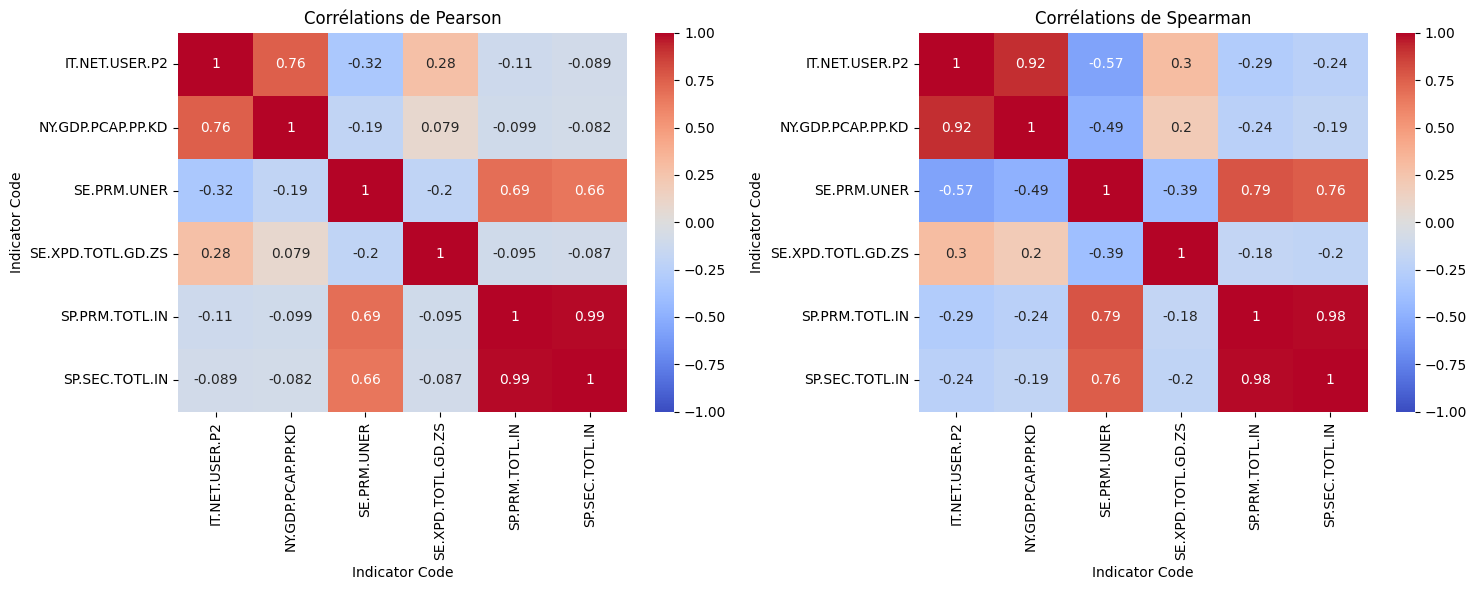

In [123]:
import matplotlib.pyplot as plt
import seaborn as sns

# Corrélations de Pearson et Spearman
correlation_pearson = tableau_pays_indicateurs.corr(method="pearson")
correlation_spearman = tableau_pays_indicateurs.corr(method="spearman")

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(
    correlation_pearson,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[0]
)
axes[0].set_title("Corrélations de Pearson")

sns.heatmap(
    correlation_spearman,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    ax=axes[1]
)
axes[1].set_title("Corrélations de Spearman")

plt.tight_layout()
plt.show()

Notre choix : conserver 3 indicateurs complémentaires.
- IT.NET.USER.P2 : accès à Internet, essentiel pour une EdTech.
- SP.SEC.TOTL.IN : taille du marché potentiel des élèves du secondaire.
- SE.XPD.TOTL.GD.ZS : effort public consacré à l'éducation.
Nous écartons provisoirement le PIB par habitant, très corrélé à l'accès à Internet, ainsi que les indicateurs de primaire et de non-scolarisation pour respecter notre seuil sur les deux matrices.

Ce choix est statistiquement cohérent, mais il réduit notre analyse à trois dimensions. Le PIB reste économiquement intéressant et pourrait être réintroduit dans une analyse commerciale ultérieure.

In [124]:
# Indicateurs finaux retenus
indicateurs_finaux = [
    "IT.NET.USER.P2",
    "SP.SEC.TOTL.IN",
    "SE.XPD.TOTL.GD.ZS"
]

# Tableau final
tableau_final = tableau_pays_indicateurs[
    indicateurs_finaux
].copy()

# Recalculer les corrélations
pearson_final = tableau_final.corr(method="pearson")
spearman_final = tableau_final.corr(method="spearman")

print("Dimensions finales :", tableau_final.shape)

display(pearson_final.round(2))
display(spearman_final.round(2))

# Vérifier automatiquement le seuil de 0,70
import numpy as np

masque = np.triu(
    np.ones(pearson_final.shape, dtype=bool),
    k=1
)

print(
    "Corrélation maximale Pearson :",
    round(pearson_final.where(masque).abs().max().max(), 2)
)

print(
    "Corrélation maximale Spearman :",
    round(spearman_final.where(masque).abs().max().max(), 2)
)

Dimensions finales : (207, 3)


Indicator Code,IT.NET.USER.P2,SP.SEC.TOTL.IN,SE.XPD.TOTL.GD.ZS
Indicator Code,,,
IT.NET.USER.P2,1.00,-0.09,0.28
SP.SEC.TOTL.IN,-0.09,1.00,-0.09
SE.XPD.TOTL.GD.ZS,0.28,-0.09,1.00


Indicator Code,IT.NET.USER.P2,SP.SEC.TOTL.IN,SE.XPD.TOTL.GD.ZS
Indicator Code,,,
IT.NET.USER.P2,1.00,-0.24,0.3
SP.SEC.TOTL.IN,-0.24,1.00,-0.2
SE.XPD.TOTL.GD.ZS,0.30,-0.20,1.0


Corrélation maximale Pearson : 0.28
Corrélation maximale Spearman : 0.3


### Analyse des corrélations et sélection finale

Les matrices de corrélation de Pearson et de Spearman ont été calculées afin d'identifier les relations statistiques entre les indicateurs sélectionnés.

L'analyse révèle notamment une corrélation très élevée entre les populations en âge de fréquenter le primaire et le secondaire (Pearson = 0,99), ainsi qu'entre l'accès à Internet et le PIB par habitant (Spearman = 0,92).

Afin de limiter la redondance statistique, trois indicateurs complémentaires ont été retenus : le taux d'utilisation d'Internet, la population en âge de fréquenter le secondaire et les dépenses publiques d'éducation en pourcentage du PIB.

Les corrélations entre ces trois indicateurs restent inférieures à 0,70 en valeur absolue, selon les deux méthodes.

Cette sélection constitue une première base d'analyse comparative des marchés internationaux pour academy. Elle ne représente toutefois pas un classement définitif des pays : les valeurs manquantes, l'ancienneté des données (2010–2015) et l'absence d'autres dimensions commerciales doivent être prises en compte.

Enfin, une corrélation statistique ne démontre pas une relation de causalité.

,IT.NET.USER.P2
count,201.000000
mean,41.413489
std,28.146353
min,0.847289
25%,14.670530
50%,41.064853
75%,63.566775
max,96.221048


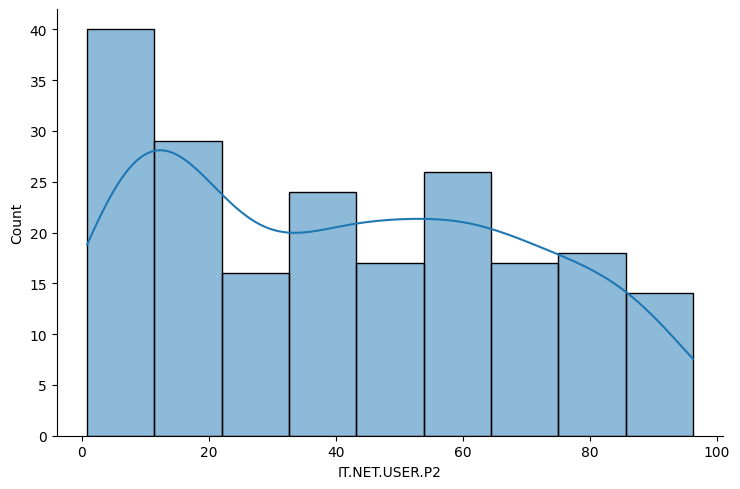

In [125]:
indicateur = "IT.NET.USER.P2"

display(tableau_final[indicateur].describe())

sns.displot(
    data=tableau_final,
    x=indicateur,
    kde=True,
    height=5,
    aspect=1.5
)

plt.show()

Ce code permet d'analyser la distribution statistique de l'un de nos indicateurs clés : le taux d'utilisation d'Internet (IT.NET.USER.P2) au sein de nos pays cibles.

Voici l'explication détaillée de chaque étape :

Définition de la variable d'intérêt : indicateur = "IT.NET.USER.P2" stocke le code de l'indicateur d'accès à Internet afin de pouvoir le réutiliser facilement dans le reste du script.

Calcul des statistiques descriptives : display(tableau_final[indicateur].describe()) calcule et affiche un résumé statistique de cette variable. Cela inclut le nombre de pays renseignés (count), la moyenne (mean), l'écart-type (std), la valeur minimale (min), les quartiles (25%, 50%, 75%) et la valeur maximale (max). C'est un excellent moyen de comprendre l'échelle de pénétration d'Internet dans notre échantillon.

Visualisation de la distribution (sns.displot) : Cette fonction de Seaborn génère un graphique combinant :

Un histogramme qui découpe les valeurs en intervalles (bins) pour afficher la fréquence des pays par tranche de taux de pénétration d'Internet.
Une courbe de densité estimée (KDE - Kernel Density Estimate) grâce au paramètre kde=True. Cette courbe lissée permet de mieux appréhender la forme générale de la distribution.
Les arguments height=5 et aspect=1.5 configurent la hauteur (5 pouces) et le ratio largeur/hauteur du graphique final.
Affichage : plt.show() finalise le traitement et affiche le graphique dans le notebook. Cela nous aide à voir d'un coup d'œil si la distribution est équilibrée ou s'il y a une forte asymétrie (par exemple, beaucoup de pays avec un accès très faible ou très élevé).


INDICATEUR : IT.NET.USER.P2


,IT.NET.USER.P2
count,201.00
mean,41.41
std,28.15
min,0.85
25%,14.67
50%,41.06
75%,63.57
max,96.22


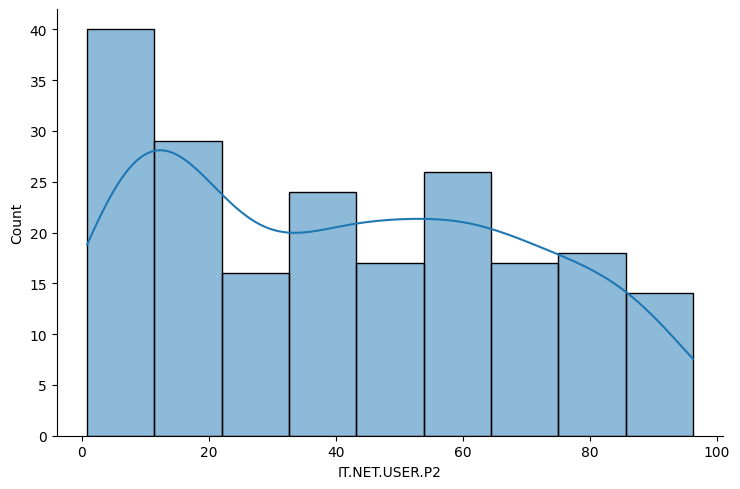


INDICATEUR : SP.SEC.TOTL.IN


,SP.SEC.TOTL.IN
count,1.930000e+02
mean,3.942532e+06
std,1.492500e+07
min,1.518000e+03
25%,1.579673e+05
50%,7.530765e+05
75%,3.000524e+06
max,1.727228e+08


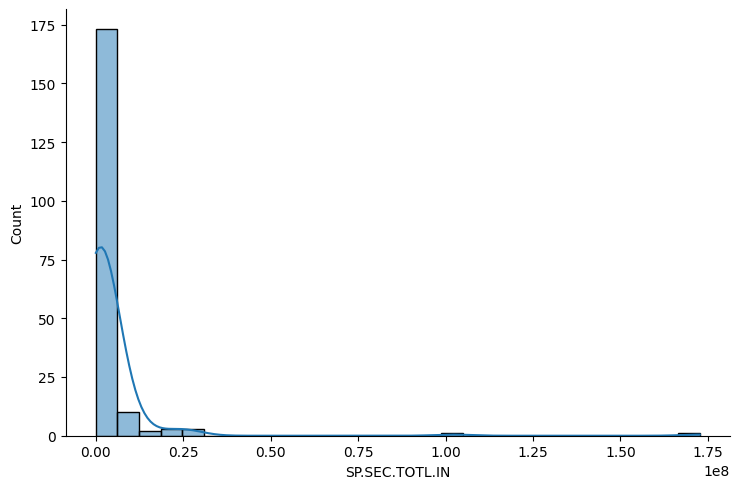


INDICATEUR : SE.XPD.TOTL.GD.ZS


,SE.XPD.TOTL.GD.ZS
count,109.00
mean,4.62
std,1.62
min,1.31
25%,3.30
50%,4.65
75%,5.71
max,8.37


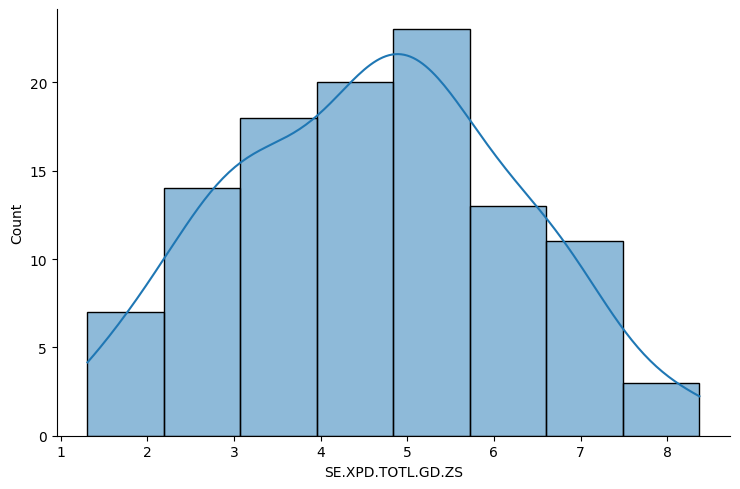

In [126]:
def analyser_indicateur(df, indicateur):
    print(f"\nINDICATEUR : {indicateur}")

    # Statistiques descriptives
    display(df[indicateur].describe().round(2))

    # Distribution
    sns.displot(
        data=df,
        x=indicateur,
        kde=True,
        height=5,
        aspect=1.5
    )

    plt.show()


# Appliquer à tous les indicateurs
for indicateur in tableau_final.columns:
    analyser_indicateur(tableau_final, indicateur)

Construire méthode quantitatve pour sélectionner les pays

In [127]:
import pandas as pd
import numpy as np
import os

# Retrouver le fichier EdStatsData.csv
fichiers = []

for dossier, sous_dossiers, noms in os.walk("/content"):
    if "drive" in sous_dossiers:
        sous_dossiers.remove("drive")

    for nom in noms:
        if nom == "EdStatsData.csv":
            fichiers.append(os.path.join(dossier, nom))

if fichiers:
    chemin = fichiers[0]
    print("Fichier trouvé :", chemin)

    data = pd.read_csv(chemin)
    print("Données chargées :", data.shape)
else:
    print("Fichier introuvable : importe EdStatsData.csv dans Colab.")

Fichier trouvé : /content/EdStatsData.csv
Données chargées : (886930, 70)


In [128]:
import pandas as pd
import os

# Rechercher les deux fichiers nécessaires
fichiers = {}

for dossier, sous_dossiers, noms in os.walk("/content"):
    if "drive" in sous_dossiers:
        sous_dossiers.remove("drive")

    for nom in noms:
        if nom in ["EdStatsData.csv", "EdStatsCountry.csv"]:
            fichiers[nom] = os.path.join(dossier, nom)

print("Fichiers trouvés :", fichiers)

# Charger les fichiers uniquement s'ils sont disponibles
if len(fichiers) == 2:
    data = pd.read_csv(fichiers["EdStatsData.csv"])
    country = pd.read_csv(fichiers["EdStatsCountry.csv"])

    print("Data :", data.shape)
    print("Country :", country.shape)
else:
    print("Il manque des fichiers. Il faut les réimporter dans Colab.")

Fichiers trouvés : {'EdStatsCountry.csv': '/content/EdStatsCountry.csv', 'EdStatsData.csv': '/content/EdStatsData.csv'}
Data : (886930, 70)
Country : (241, 32)


In [129]:
import pandas as pd
import os

# 1. Retrouver les fichiers
chemin_data = "/content/EdStatsData.csv"
chemin_country = "/content/EdStatsCountry.csv"

# 2. Charger les données
data = pd.read_csv(chemin_data)
country = pd.read_csv(chemin_country)

# 3. Conserver uniquement les vrais pays
codes_pays = country.loc[
    country["Region"].notna(), "Country Code"
]

# 4. Indicateurs et années sélectionnés
indicateurs_finaux = [
    "IT.NET.USER.P2",      # Accès à Internet
    "SP.SEC.TOTL.IN",      # Population en âge d'être au secondaire
    "SE.XPD.TOTL.GD.ZS"   # Dépenses publiques d'éducation (% PIB)
]

annees = [str(a) for a in range(2010, 2016)]

# 5. Filtrer les données
df = data.loc[
    data["Country Code"].isin(codes_pays)
    & data["Indicator Code"].isin(indicateurs_finaux),
    ["Country Code", "Country Name", "Indicator Code"] + annees
].copy()

# 6. Conserver au moins 4 années renseignées
df = df[df[annees].notna().sum(axis=1) >= 4]

# 7. Calculer la moyenne historique
df["valeur_moyenne"] = df[annees].mean(axis=1)

# 8. Créer le tableau pays × indicateurs
tableau_final = df.pivot_table(
    index=["Country Code", "Country Name"],
    columns="Indicator Code",
    values="valeur_moyenne",
    aggfunc="mean"
).reindex(columns=indicateurs_finaux)

# 9. Garder les pays avec les 3 indicateurs
pays_complets = tableau_final.dropna().copy()

# 10. Normaliser les indicateurs
scores = pays_complets.rank(pct=True) * 100

# 11. Calculer le score pondéré
scores["Score academy"] = (
    scores["IT.NET.USER.P2"] * 0.40
    + scores["SP.SEC.TOTL.IN"] * 0.40
    + scores["SE.XPD.TOTL.GD.ZS"] * 0.20
)

# 12. Classer les pays
classement_pays = scores.sort_values(
    "Score academy",
    ascending=False
)

print("Nombre de pays évalués :", len(classement_pays))
display(classement_pays.head(15).round(2))

# 13. Extraire les 10 pays prioritaires
pays_prioritaires = (
    classement_pays.head(10)
    .index.get_level_values("Country Name")
    .tolist()
)

print("\nPays prioritaires :", pays_prioritaires)

Nombre de pays évalués : 103


,Indicator Code,IT.NET.USER.P2,SP.SEC.TOTL.IN,SE.XPD.TOTL.GD.ZS,Score academy
Country Code,Country Name,,,,
GBR,United Kingdom,95.15,86.41,73.79,87.38
DEU,Germany,91.26,91.26,54.37,83.88
FRA,France,87.38,87.38,69.90,83.88
USA,United States,77.67,97.09,63.11,82.52
JPN,Japan,92.23,90.29,27.18,78.45
BRA,Brazil,56.31,96.12,76.70,76.31
SWE,Sweden,97.09,38.83,96.12,73.59
NLD,Netherlands,96.12,51.46,68.93,72.82
MYS,Malaysia,66.02,78.64,66.02,71.07



Pays prioritaires : ['United Kingdom', 'Germany', 'France', 'United States', 'Japan', 'Brazil', 'Sweden', 'Netherlands', 'Malaysia', 'Denmark']


In [130]:
print("Pays dans le tableau :", len(tableau_final))

print("\nValeurs disponibles par indicateur :")
print(tableau_final.notna().sum())

print("\nPays avec les 3 indicateurs :")
print(len(tableau_final.dropna()))

Pays dans le tableau : 206

Valeurs disponibles par indicateur :
Indicator Code
IT.NET.USER.P2       201
SP.SEC.TOTL.IN       193
SE.XPD.TOTL.GD.ZS    109
dtype: int64

Pays avec les 3 indicateurs :
103


In [131]:
# Vérifier les données déjà présentes dans la session
variables = [
    "data_final",
    "data_reduit",
    "data_agregation",
    "tableau_pays_indicateurs",
    "tableau_final"
]

for nom in variables:
    if nom in globals():
        objet = globals()[nom]
        print(f"OK - {nom} : {objet.shape}")
    else:
        print(f"ABSENT - {nom}")

OK - data_final : (784310, 69)
OK - data_reduit : (1284, 10)
OK - data_agregation : (1003, 11)
OK - tableau_pays_indicateurs : (207, 6)
OK - tableau_final : (206, 3)


In [132]:
import os

fichiers_attendus = [
    "EdStatsCountry-Series.csv",
    "EdStatsCountry.csv",
    "EdStatsFootNote.csv",
    "EdStatsData.csv",
    "EdStatsSeries.csv"
]

for fichier in fichiers_attendus:
    chemin = os.path.join("/content", fichier)

    if os.path.exists(chemin):
        print("OK :", fichier)
    else:
        print("MANQUANT :", fichier)

OK : EdStatsCountry-Series.csv
OK : EdStatsCountry.csv
OK : EdStatsFootNote.csv
OK : EdStatsData.csv
OK : EdStatsSeries.csv


In [133]:
from google.colab import files

fichiers = files.upload()

In [134]:
import os

fichiers_attendus = [
    "EdStatsCountry-Series.csv",
    "EdStatsCountry.csv",
    "EdStatsFootNote.csv",
    "EdStatsData.csv",
    "EdStatsSeries.csv"
]

for fichier in fichiers_attendus:
    if os.path.exists("/content/" + fichier):
        print("OK :", fichier)
    else:
        print("MANQUANT :", fichier)

OK : EdStatsCountry-Series.csv
OK : EdStatsCountry.csv
OK : EdStatsFootNote.csv
OK : EdStatsData.csv
OK : EdStatsSeries.csv


In [ ]:
import pandas as pd
import numpy as np

# Charger les cinq fichiers de la Banque mondiale
df1 = pd.read_csv("/content/EdStatsCountry-Series.csv")
df2 = pd.read_csv("/content/EdStatsCountry.csv")
df3 = pd.read_csv("/content/EdStatsFootNote.csv")
df4 = pd.read_csv("/content/EdStatsData.csv")
df5 = pd.read_csv("/content/EdStatsSeries.csv")

# Vérifier les dimensions
for nom, df in [
    ("Country-Series", df1),
    ("Country", df2),
    ("FootNote", df3),
    ("Data", df4),
    ("Series", df5)
]:
    print(f"{nom} : {df.shape}")

In [ ]:
# Supprimer uniquement les colonnes 100 % vides
df1 = df1.dropna(axis=1, how="all")
df2 = df2.dropna(axis=1, how="all")
df3 = df3.dropna(axis=1, how="all")
df4 = df4.dropna(axis=1, how="all")
df5 = df5.dropna(axis=1, how="all")

# Vérifier les nouvelles dimensions
for nom, df in [
    ("Country-Series", df1),
    ("Country", df2),
    ("FootNote", df3),
    ("Data", df4),
    ("Series", df5)
]:
    print(f"{nom} : {df.shape}")

In [ ]:
# Identifier les pays disposant d'une région
country_clean = df2[df2["Region"].notna()].copy()

# Récupérer leurs codes
codes_pays = country_clean["Country Code"].unique()

# Filtrer les données éducatives
data_final = df4[
    df4["Country Code"].isin(codes_pays)
].copy()

# Vérifier les résultats
print("Pays et territoires retenus :", country_clean.shape[0])
print("Lignes de données conservées :", data_final.shape[0])
print("Dimensions de data_final :", data_final.shape)

In [135]:
# Vérifier le tableau final
print("Dimensions :", tableau_final.shape)

print("\nIndicateurs disponibles :")
print(tableau_final.columns.tolist())

print("\nValeurs manquantes :")
print(tableau_final.isna().sum())

print("\nAperçu des données :")
display(tableau_final.head())

Dimensions : (206, 3)

Indicateurs disponibles :
['IT.NET.USER.P2', 'SP.SEC.TOTL.IN', 'SE.XPD.TOTL.GD.ZS']

Valeurs manquantes :
Indicator Code
IT.NET.USER.P2        5
SP.SEC.TOTL.IN       13
SE.XPD.TOTL.GD.ZS    97
dtype: int64

Aperçu des données :


,Indicator Code,IT.NET.USER.P2,SP.SEC.TOTL.IN,SE.XPD.TOTL.GD.ZS
Country Code,Country Name,,,
ABW,Aruba,76.056871,7.526667e+03,6.453882
AFG,Afghanistan,5.935758,4.358409e+06,3.334565
AGO,Angola,7.316667,3.248381e+06,NaN
ALB,Albania,54.868149,3.676903e+05,NaN
AND,Andorra,89.207404,NaN,2.987752


In [136]:
# Conserver une copie du tableau initial
tableau_reference = tableau_final.copy()

# Identifier les pays avec les 3 indicateurs renseignés
tableau_complet = tableau_reference.dropna(
    subset=[
        "IT.NET.USER.P2",
        "SP.SEC.TOTL.IN",
        "SE.XPD.TOTL.GD.ZS"
    ]
).copy()

# Mesurer l'effet du filtrage
nb_initial = len(tableau_reference)
nb_complet = len(tableau_complet)
nb_exclus = nb_initial - nb_complet

print("Pays et territoires initiaux :", nb_initial)
print("Pays avec 3 indicateurs :", nb_complet)
print("Pays exclus du classement :", nb_exclus)
print("Couverture du classement :", round(nb_complet / nb_initial * 100, 2), "%")

display(tableau_complet.head())

Pays et territoires initiaux : 206
Pays avec 3 indicateurs : 103
Pays exclus du classement : 103
Couverture du classement : 50.0 %


,Indicator Code,IT.NET.USER.P2,SP.SEC.TOTL.IN,SE.XPD.TOTL.GD.ZS
Country Code,Country Name,,,
ABW,Aruba,76.056871,7.526667e+03,6.453882
AFG,Afghanistan,5.935758,4.358409e+06,3.334565
ARG,Argentina,57.407177,4.152966e+06,5.264714
AUS,Australia,81.083619,1.727443e+06,5.212932
AUT,Austria,79.915792,7.204075e+05,5.580354


In [137]:
# Étape 7 : calcul du score d'attractivité

classement = tableau_complet.copy()

# Transformer chaque indicateur en rang percentile (0 à 1)
classement["score_internet"] = (
    classement["IT.NET.USER.P2"].rank(pct=True)
)

classement["score_population"] = (
    classement["SP.SEC.TOTL.IN"].rank(pct=True)
)

classement["score_education"] = (
    classement["SE.XPD.TOTL.GD.ZS"].rank(pct=True)
)

# Score pondéré sur 100
classement["score_global"] = 100 * (
    0.40 * classement["score_internet"]
    + 0.40 * classement["score_population"]
    + 0.20 * classement["score_education"]
)

# Trier les pays du plus attractif au moins attractif
classement = classement.sort_values(
    by="score_global",
    ascending=False
)

# Ajouter un rang
classement["rang"] = range(1, len(classement) + 1)

# Afficher les 10 premiers pays
display(
    classement[
        [
            "rang",
            "score_internet",
            "score_population",
            "score_education",
            "score_global"
        ]
    ].head(10).round(2)
)

,Indicator Code,rang,score_internet,score_population,score_education,score_global
Country Code,Country Name,,,,,
GBR,United Kingdom,1,0.95,0.86,0.74,87.38
DEU,Germany,2,0.91,0.91,0.54,83.88
FRA,France,3,0.87,0.87,0.70,83.88
USA,United States,4,0.78,0.97,0.63,82.52
JPN,Japan,5,0.92,0.90,0.27,78.45
BRA,Brazil,6,0.56,0.96,0.77,76.31
SWE,Sweden,7,0.97,0.39,0.96,73.59
NLD,Netherlands,8,0.96,0.51,0.69,72.82
MYS,Malaysia,9,0.66,0.79,0.66,71.07


Tester la robustesse du classement

In [138]:
# Étape 8 : analyse de sensibilité des pondérations

scenarios = {
    "equilibre": (1/3, 1/3, 1/3),
    "digital": (0.50, 0.30, 0.20),
    "marche": (0.30, 0.50, 0.20)
}

for nom, (w_internet, w_population, w_education) in scenarios.items():

    classement[f"score_{nom}"] = 100 * (
        w_internet * classement["score_internet"]
        + w_population * classement["score_population"]
        + w_education * classement["score_education"]
    )

    classement[f"rang_{nom}"] = (
        classement[f"score_{nom}"]
        .rank(ascending=False, method="min")
        .astype(int)
    )

# Comparer les rangs des 10 pays du classement initial
comparaison = classement[
    [
        "rang",
        "rang_equilibre",
        "rang_digital",
        "rang_marche"
    ]
].head(10)

display(comparaison)

# Vérifier les scores exacts de l'Allemagne et de la France
display(
    classement.loc[
        [["DEU", "Germany"], ["FRA", "France"]],
        ["score_global"]
    ]
)

,Indicator Code,rang,rang_equilibre,rang_digital,rang_marche
Country Code,Country Name,,,,
GBR,United Kingdom,1,1,1,1
DEU,Germany,2,4,2,3
FRA,France,3,2,3,4
USA,United States,4,3,4,2
JPN,Japan,5,14,6,6
BRA,Brazil,6,6,13,5
SWE,Sweden,7,5,5,13
NLD,Netherlands,8,9,8,12
MYS,Malaysia,9,13,16,10


,Indicator Code,score_global
Country Code,Country Name,
DEU,Germany,83.883495
FRA,France,83.883495


Corriger les rangs et mesurer leur stabilité

In [139]:
# Corriger les rangs pour respecter les ex aequo
classement["rang"] = (
    classement["score_global"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Mesurer l'écart entre le meilleur et le moins bon rang
colonnes_rangs = [
    "rang",
    "rang_equilibre",
    "rang_digital",
    "rang_marche"
]

classement["meilleur_rang"] = classement[colonnes_rangs].min(axis=1)
classement["moins_bon_rang"] = classement[colonnes_rangs].max(axis=1)

classement["amplitude_rang"] = (
    classement["moins_bon_rang"]
    - classement["meilleur_rang"]
)

# Afficher les 10 premiers pays du classement initial
display(
    classement[
        [
            "rang",
            "score_global",
            "meilleur_rang",
            "moins_bon_rang",
            "amplitude_rang"
        ]
    ]
    .sort_values("score_global", ascending=False)
    .head(10)
    .round(2)
)

,Indicator Code,rang,score_global,meilleur_rang,moins_bon_rang,amplitude_rang
Country Code,Country Name,,,,,
GBR,United Kingdom,1,87.38,1,1,0
DEU,Germany,2,83.88,2,4,2
FRA,France,3,83.88,2,4,2
USA,United States,4,82.52,2,4,2
JPN,Japan,5,78.45,5,14,9
BRA,Brazil,6,76.31,5,13,8
SWE,Sweden,7,73.59,5,13,8
NLD,Netherlands,8,72.82,8,12,4
MYS,Malaysia,9,71.07,9,16,7


### Conclusion de l'analyse multicritère

L'analyse des données EdStats de la Banque mondiale sur la période 2010–2015 a permis de construire un indice d'attractivité pour évaluer les marchés potentiels d'academy.

Trois indicateurs ont été retenus : le taux d'utilisation d'Internet, la population en âge de fréquenter l'enseignement secondaire et les dépenses publiques d'éducation en pourcentage du PIB.

Après traitement des valeurs manquantes, 103 pays et territoires sur 206 disposent des trois indicateurs nécessaires au classement, soit une couverture de 50 %.

Un score composite a été calculé à partir de rangs percentiles, selon une pondération initiale de 40 % pour Internet, 40 % pour la population scolaire et 20 % pour les dépenses éducatives.

**Principaux résultats :**

- Le Royaume-Uni occupe la première position dans les quatre scénarios testés.
- L'Allemagne, la France et les États-Unis restent systématiquement dans les quatre premières positions.
- Le Brésil présente un potentiel démographique intéressant, mais son classement se dégrade lorsque l'accès à Internet devient prioritaire.
- Le Japon, la Suède, les Pays-Bas, la Malaisie et le Danemark présentent des résultats plus sensibles aux pondérations.

**Limites de l'étude :**

Les données sont historiques et ne permettent pas d'évaluer directement les conditions de marché en 2026. De plus, 50 % des pays et territoires sont exclus du classement en raison de valeurs manquantes. Enfin, les pondérations reposent sur des hypothèses métier et les trois indicateurs ne couvrent pas l'ensemble des facteurs de réussite commerciale.

**Recommandation :**

Le Royaume-Uni, l'Allemagne, la France et les États-Unis constituent une première liste de marchés à approfondir. Avant toute décision d'implantation, academy devra compléter cette analyse par des données actualisées sur la concurrence, la demande EdTech, le pouvoir d'achat, la réglementation et les coûts d'entrée sur chaque marché.

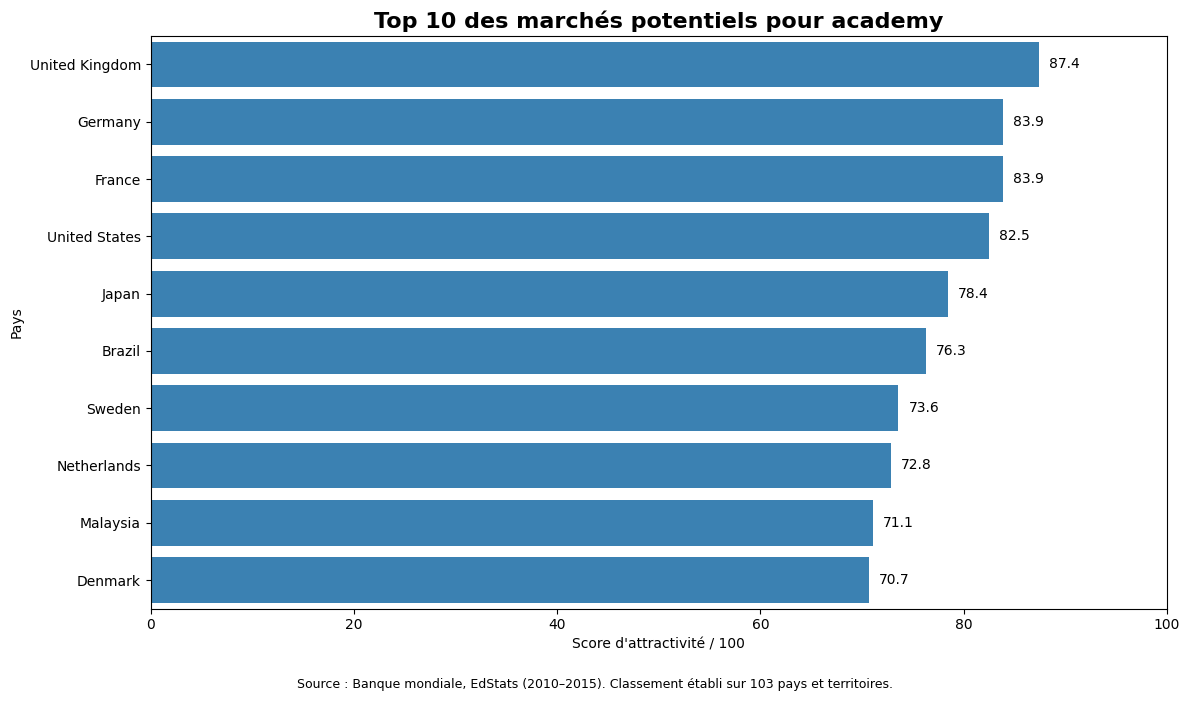

In [140]:
import matplotlib.pyplot as plt
import seaborn as sns

# Récupérer les 10 premiers pays
top10 = classement.head(10).reset_index()

# Créer le graphique
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10,
    x="score_global",
    y="Country Name",
    color="#2784C6"
)

plt.title(
    "Top 10 des marchés potentiels pour academy",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Score d'attractivité / 100")
plt.ylabel("Pays")
plt.xlim(0, 100)

# Afficher les scores au bout des barres
for i, score in enumerate(top10["score_global"]):
    plt.text(
        score + 1,
        i,
        f"{score:.1f}",
        va="center"
    )

plt.figtext(
    0.5, 0.01,
    "Source : Banque mondiale, EdStats (2010–2015). "
    "Classement établi sur 103 pays et territoires.",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])

# Enregistrer le graphique
plt.savefig(
    "/content/academy_top10_pays.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()